# Sparsification Experiments

## Step 1: Data Creation (Rings + GMM)

This notebook starts with the dataset setup only. It creates the ring toy data and GMM data, then plots them in the same style used in `sparse_test.ipynb`.


In [1]:
%load_ext autoreload
%autoreload 2

import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
sys.path.insert(0, "../scripts")

from sparsification import (
    sparsify_test_diag_eot_knn,
    sparsify_top_percentage_neighbors,
    sparsify_top_percentage_mass,
    sparsify_values_above_percentage_top,
    quantile_mapping_diag_blocks,
)

from ne_aligned_utils.toy_utils import make_circle_data
from ne_aligned_utils.data import make_joint_gmm

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True


In [2]:
# Shared seed
seed = 0

# Ring data settings
n0_ring = 1000
n1_ring = 5000

# GMM data settings
gmm_n0 = 600
gmm_n1 = 600
gmm_p = 1000
gmm_q = 6
gmm_theta = 3.0


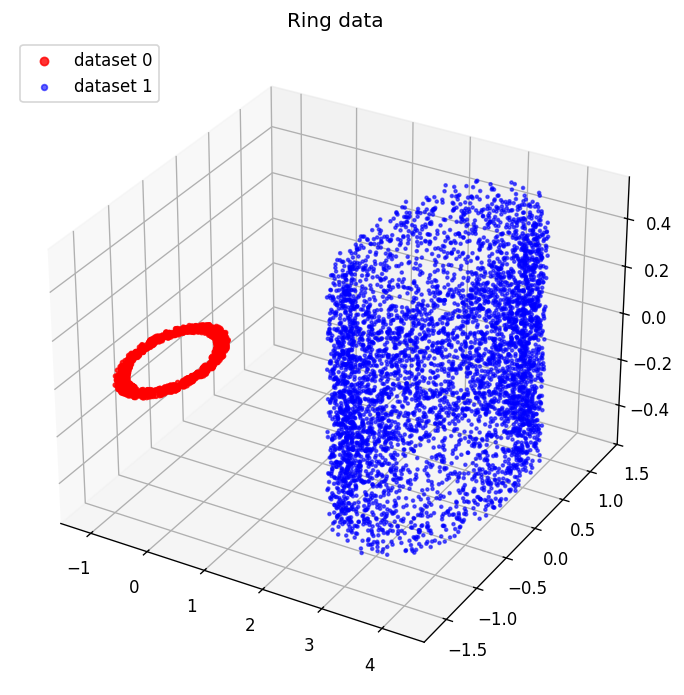

ring observed data: x0=(1000, 3), x1=(5000, 3)


In [3]:
# Ring data (observed)
x0_ring, x1_ring = make_circle_data(n0=n0_ring, n1=n1_ring, seed=seed)

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x0_ring[:, 0], x0_ring[:, 1], x0_ring[:, 2], c="red", s=6, alpha=0.8, label="dataset 0")
ax.scatter(x1_ring[:, 0], x1_ring[:, 1], x1_ring[:, 2], c="blue", s=3, alpha=0.6, label="dataset 1")
ax.set_title("Ring data")
ax.view_init(elev=30, azim=-60)
ax.legend(markerscale=2, loc="upper left")
plt.show()

print(f"ring observed data: x0={x0_ring.shape}, x1={x1_ring.shape}")


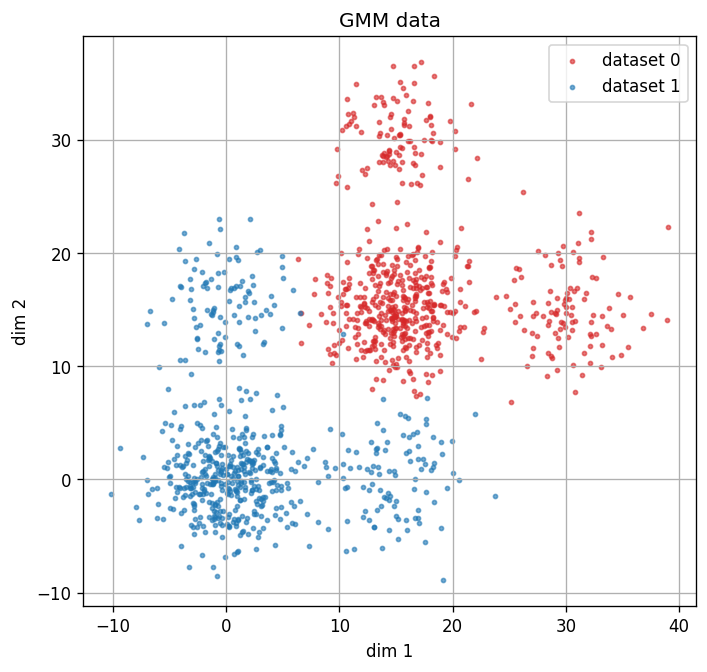

gmm observed data: x0=(600, 1000), x1=(600, 1000) (p=1000, q=6, theta=3.0)


In [4]:
# GMM data with batch effect (observed)
gmm0_obs, gmm1_obs = make_joint_gmm(
    n0=gmm_n0,
    n1=gmm_n1,
    p=gmm_p,
    q=gmm_q,
    theta=gmm_theta,
    seed=seed,
    clean=False,
)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(gmm0_obs[:, 0], gmm0_obs[:, 1], s=6, c="tab:red", alpha=0.6, label="dataset 0")
ax.scatter(gmm1_obs[:, 0], gmm1_obs[:, 1], s=6, c="tab:blue", alpha=0.6, label="dataset 1")
ax.set_title("GMM data")
ax.set_xlabel("dim 1")
ax.set_ylabel("dim 2")
ax.set_aspect("equal")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

print(
    f"gmm observed data: x0={gmm0_obs.shape}, x1={gmm1_obs.shape} "
    f"(p={gmm_p}, q={gmm_q}, theta={gmm_theta})"
)


## Step 2: Compute OT Plans for Both Datasets

Compute one OT plan for ring data and one OT plan for GMM data, then print both plan matrices.


In [5]:
from ne_aligned_utils.utils import compute_ot_plan
from matplotlib.colors import LogNorm

# OT solver settings
eps_times_ring = 1
eps_times_gmm = 1
tol = 1e-12
maxIter = int(1e4)

# Rings OT plan
P_ring = compute_ot_plan(
    x0_ring,
    x1_ring,
    eps_times=0.1,
    tol=tol,
    maxIter=maxIter,
)

# GMM OT plan
P_gmm = compute_ot_plan(
    gmm0_obs,
    gmm1_obs,
    eps_times=0.1,
    tol=tol,
    maxIter=maxIter,
)

print(f"P_ring shape={P_ring.shape}, sum={P_ring.sum():.6f}")
print(f"P_gmm shape={P_gmm.shape}, sum={P_gmm.sum():.6f}")

def _lognorm_for_plan(P):
    vals = P[P > 0]
    if vals.size == 0:
        return None
    vmin = float(np.quantile(vals, 0.01))
    vmax = float(np.quantile(vals, 0.995))
    vmin = max(vmin, 1e-16)
    if vmax <= vmin:
        vmax = float(vals.max()) if float(vals.max()) > vmin else vmin * 10.0
    return LogNorm(vmin=vmin, vmax=vmax)


P_ring shape=(1000, 5000), sum=1.000000
P_gmm shape=(600, 600), sum=1.000000


In [6]:
# Sort GMM OT plan by cluster labels
# (recompute labels with same seed/settings used to generate gmm0_obs, gmm1_obs)
_, _, clusters0, clusters1 = make_joint_gmm(
    n0=gmm_n0,
    n1=gmm_n1,
    p=gmm_p,
    q=gmm_q,
    theta=gmm_theta,
    seed=seed,
    clean=True,
)
sorted_gmm_idx0 = np.argsort(clusters0)
sorted_gmm_idx1 = np.argsort(clusters1)
P_gmm = P_gmm[np.ix_(sorted_gmm_idx0, sorted_gmm_idx1)]


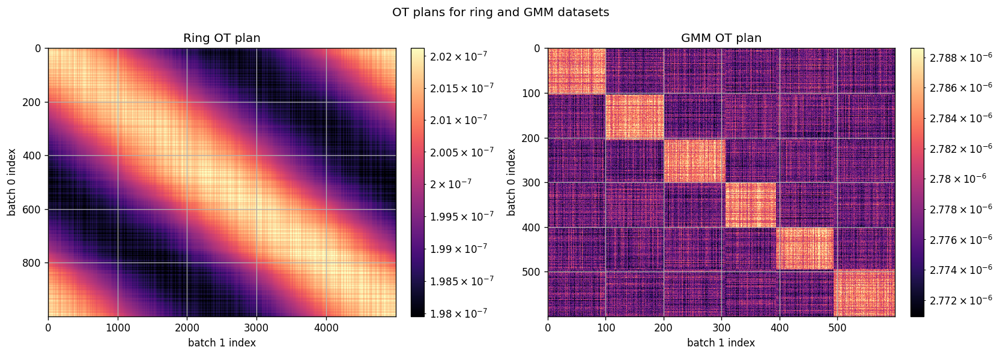

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, P, title in [
    (axes[0], P_ring, "Ring OT plan"),
    (axes[1], P_gmm, "GMM OT plan"),
]:
    norm = _lognorm_for_plan(P)
    disp = np.array(P, copy=True)
    disp[disp <= 0] = np.nan
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto", norm=norm)
    ax.set_title(title)
    ax.set_xlabel("batch 1 index")
    ax.set_ylabel("batch 0 index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle("OT plans for ring and GMM datasets")
fig.tight_layout()
plt.show()

## Step 3: Build Block Matrices

In [8]:
from ne_aligned_utils.toy_utils import get_diag_graph

def build_four_block_matrix(P):
    A = get_diag_graph(P)  # SVD-based 4-block matrix
    # keep original get_diag_graph values before sparsification
    return A

# Step 3: build 4-block matrices for both datasets
A_ring = build_four_block_matrix(P_ring)
A_gmm  = build_four_block_matrix(P_gmm)

print(f"A_ring shape={A_ring.shape}, sum={A_ring.sum():.6f}")
print(f"A_gmm  shape={A_gmm.shape}, sum={A_gmm.sum():.6f}")


A_ring shape=(6000, 6000), sum=7.198789
A_gmm  shape=(1200, 1200), sum=3.996628


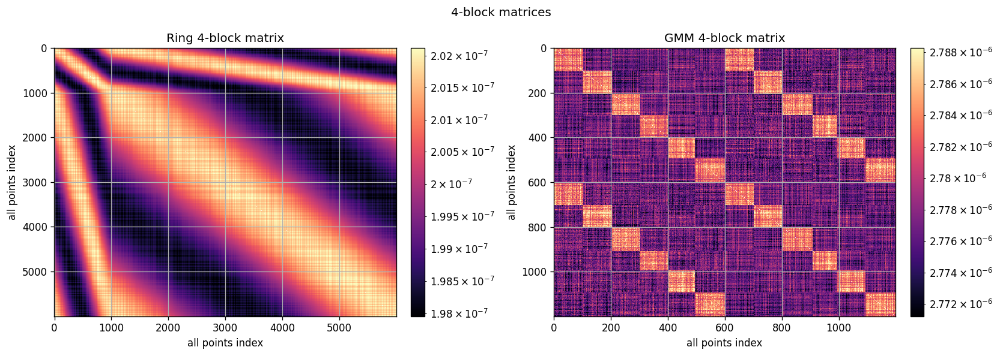

In [9]:
# optional visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, A, title in [
    (axes[0], A_ring, "Ring 4-block matrix"),
    (axes[1], A_gmm,  "GMM 4-block matrix"),
]:
    vals = A[A > 0]
    norm = LogNorm(
        vmin=max(float(np.quantile(vals, 0.01)), 1e-16),
        vmax=float(np.quantile(vals, 0.995))
    ) if vals.size > 0 else None

    disp = np.array(A, copy=True)
    disp[disp <= 0] = np.nan
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto", norm=norm)
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle("4-block matrices")
fig.tight_layout()
plt.show()

## Step 4: Sparsification

### kNN

In [10]:
# Cell 1/5: test_diag_eot KNN sparsification on 4-block matrices (0 -> black)
from matplotlib.colors import LogNorm
import numpy as np
import matplotlib.pyplot as plt

k_knn = 15

ring_knn = sparsify_test_diag_eot_knn(A_ring, n0=n0_ring, n1=n1_ring, k=k_knn, scale_cross_by_ratio=True)
gmm_knn = sparsify_test_diag_eot_knn(A_gmm, n0=gmm_n0, n1=gmm_n1, k=k_knn, scale_cross_by_ratio=True)

A_ring_sparse_knn = ring_knn.matrix
A_gmm_sparse_knn = gmm_knn.matrix

print("Ring KNN stats:", ring_knn.stats)
print("GMM  KNN stats:", gmm_knn.stats)

Ring KNN stats: {'method': 'test_diag_eot_knn', 'shape': (6000, 6000), 'nnz': 986268, 'density': 0.027396333333333335, 'sum': 0.19918703134543922, 'n0': 1000, 'n1': 5000, 'k': 15, 'k_cross': 75, 'scale_cross_by_ratio': True, 'auto_scale_row_col': True, 'k00_row': 15, 'k00_col': 15, 'k01_row': 75, 'k01_col': 15, 'k10_row': 15, 'k10_col': 75, 'k11_row': 75, 'k11_col': 75}
GMM  KNN stats: {'method': 'test_diag_eot_knn', 'shape': (1200, 1200), 'nnz': 60476, 'density': 0.04199722222222222, 'sum': 0.16849575561718946, 'n0': 600, 'n1': 600, 'k': 15, 'k_cross': 15, 'scale_cross_by_ratio': True, 'auto_scale_row_col': True, 'k00_row': 15, 'k00_col': 15, 'k01_row': 15, 'k01_col': 15, 'k10_row': 15, 'k10_col': 15, 'k11_row': 15, 'k11_col': 15}


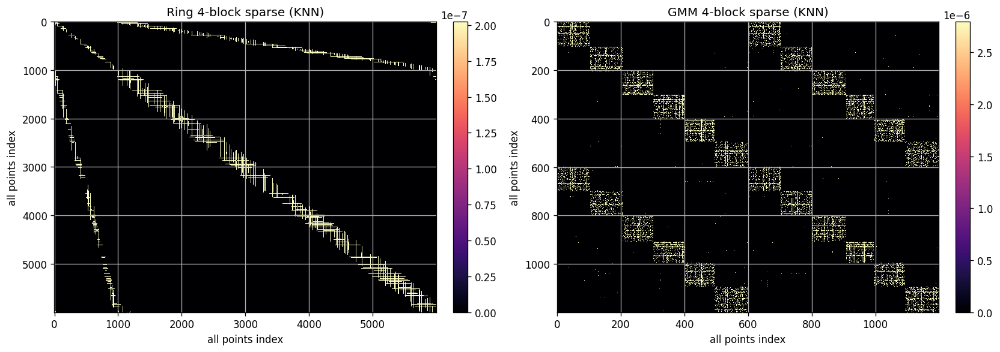

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, A, title in [
    (axes[0], A_ring_sparse_knn, "Ring 4-block sparse (KNN)"),
    (axes[1], A_gmm_sparse_knn, "GMM 4-block sparse (KNN)"),
]:
    disp = np.maximum(A, 0.0)  # keep zeros as zeros
    im = ax.imshow(
        disp,
        cmap="magma",
        interpolation="nearest",
        aspect="auto",
        vmin=0.0,   # force zero -> colormap minimum (black in magma)
        vmax=float(disp.max()) if disp.size else 1.0,
    )
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.tight_layout()
plt.show()


### top percentage of neighbors

In [13]:
# Cell 2/5: Top percentage of neighbors + plot (0 -> black, linear scale)
import numpy as np
import matplotlib.pyplot as plt

p_neighbors = 0.05

ring_pct_neighbors = sparsify_top_percentage_neighbors(A_ring, percentage=p_neighbors, n0=n0_ring, n1=n1_ring, ensure_nonempty=True)
gmm_pct_neighbors  = sparsify_top_percentage_neighbors(A_gmm,  percentage=p_neighbors, n0=gmm_n0, n1=gmm_n1, ensure_nonempty=True)

A_ring_sparse_pct_neighbors = ring_pct_neighbors.matrix
A_gmm_sparse_pct_neighbors  = gmm_pct_neighbors.matrix

print("Ring pct-neighbors stats:", ring_pct_neighbors.stats)
print("GMM  pct-neighbors stats:", gmm_pct_neighbors.stats)




Ring pct-neighbors stats: {'method': 'top_percentage_neighbors', 'shape': (6000, 6000), 'nnz': 2902684, 'density': 0.08063011111111111, 'sum': 0.5859580879039207, 'percentage': 0.05, 'n0': 1000, 'n1': 5000, 'blockwise': True}
GMM  pct-neighbors stats: {'method': 'top_percentage_neighbors', 'shape': (1200, 1200), 'nnz': 109064, 'density': 0.07573888888888888, 'sum': 0.3037833518066315, 'percentage': 0.05, 'n0': 600, 'n1': 600, 'blockwise': True}


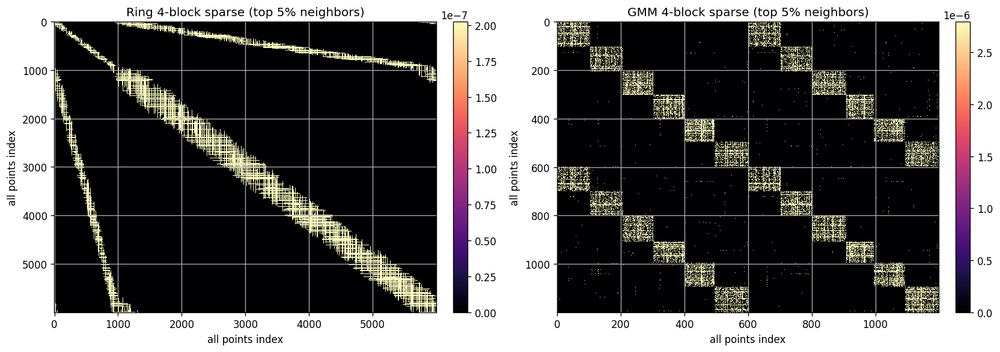

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, A, title in [
    (axes[0], A_ring_sparse_pct_neighbors, f"Ring 4-block sparse (top {p_neighbors:.0%} neighbors)"),
    (axes[1], A_gmm_sparse_pct_neighbors,  f"GMM 4-block sparse (top {p_neighbors:.0%} neighbors)"),
]:
    disp = np.maximum(A, 0.0)
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto",
                   vmin=0.0, vmax=float(disp.max()) if disp.size else 1.0)
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### top percentage of probability mass

In [15]:
# Cell 3/5: Top percentage of probability mass + plot (0 -> black, linear scale)
import numpy as np
import matplotlib.pyplot as plt

p_mass = 0.10

ring_pct_mass = sparsify_top_percentage_mass(A_ring, percentage=p_mass, n0=n0_ring, n1=n1_ring, ensure_nonempty=True)
gmm_pct_mass  = sparsify_top_percentage_mass(A_gmm,  percentage=p_mass, n0=gmm_n0, n1=gmm_n1, ensure_nonempty=True)

A_ring_sparse_pct_mass = ring_pct_mass.matrix
A_gmm_sparse_pct_mass  = gmm_pct_mass.matrix

print("Ring pct-mass stats:", ring_pct_mass.stats)
print("GMM  pct-mass stats:", gmm_pct_mass.stats)



Ring pct-mass stats: {'method': 'top_percentage_mass', 'shape': (6000, 6000), 'nnz': 4963352, 'density': 0.13787088888888888, 'sum': 1.001527917187674, 'percentage': 0.1, 'n0': 1000, 'n1': 5000, 'blockwise': True}
GMM  pct-mass stats: {'method': 'top_percentage_mass', 'shape': (1200, 1200), 'nnz': 183590, 'density': 0.12749305555555557, 'sum': 0.5111954248191475, 'percentage': 0.1, 'n0': 600, 'n1': 600, 'blockwise': True}


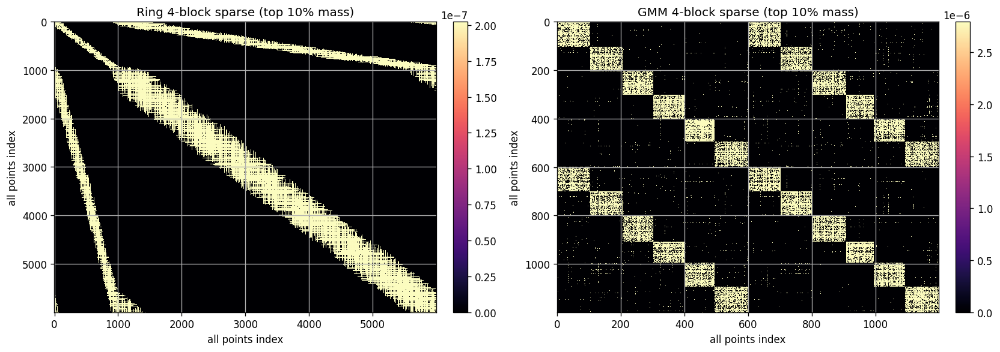

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, A, title in [
    (axes[0], A_ring_sparse_pct_mass, f"Ring 4-block sparse (top {p_mass:.0%} mass)"),
    (axes[1], A_gmm_sparse_pct_mass,  f"GMM 4-block sparse (top {p_mass:.0%} mass)"),
]:
    disp = np.maximum(A, 0.0)
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto",
                   vmin=0.0, vmax=float(disp.max()) if disp.size else 1.0)
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### values above percentage of top value

In [17]:
# Cell 4/5: Values above percentage of top value + plot (0 -> black, linear scale)
from sparsification import sparsify_values_above_percentage_top
import numpy as np
import matplotlib.pyplot as plt

p_top = 0.995

ring_above_top = sparsify_values_above_percentage_top(A_ring, percentage=p_top, n0=n0_ring, n1=n1_ring, ensure_nonempty=True)
gmm_above_top  = sparsify_values_above_percentage_top(A_gmm,  percentage=p_top, n0=gmm_n0, n1=gmm_n1, ensure_nonempty=True)

A_ring_sparse_above_top = ring_above_top.matrix
A_gmm_sparse_above_top  = gmm_above_top.matrix

print("Ring above-top stats:", ring_above_top.stats)
print("GMM  above-top stats:", gmm_above_top.stats)




Ring above-top stats: {'method': 'values_above_percentage_top', 'shape': (6000, 6000), 'nnz': 11715124, 'density': 0.32542011111111113, 'sum': 2.360637727935821, 'percentage': 0.995, 'n0': 1000, 'n1': 5000, 'blockwise': True}
GMM  above-top stats: {'method': 'values_above_percentage_top', 'shape': (1200, 1200), 'nnz': 1276160, 'density': 0.8862222222222222, 'sum': 3.5455706614833753, 'percentage': 0.995, 'n0': 600, 'n1': 600, 'blockwise': True}


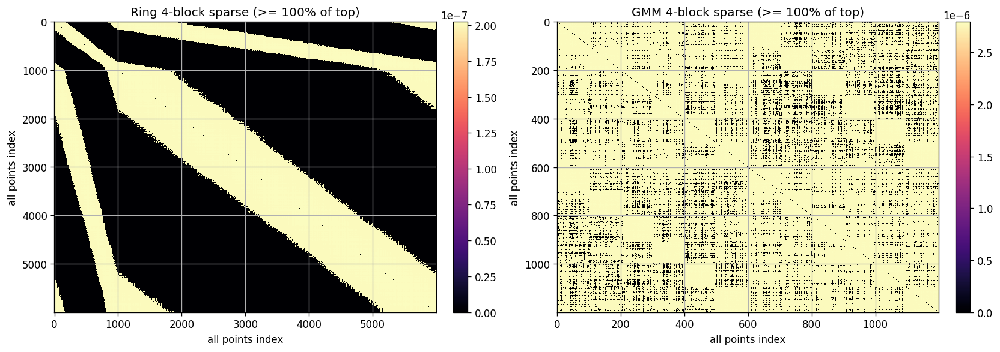

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, A, title in [
    (axes[0], A_ring_sparse_above_top, f"Ring 4-block sparse (>= {p_top:.0%} of top)"),
    (axes[1], A_gmm_sparse_above_top,  f"GMM 4-block sparse (>= {p_top:.0%} of top)"),
]:
    disp = np.maximum(A, 0.0)
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto",
                   vmin=0.0, vmax=float(disp.max()) if disp.size else 1.0)
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### quantile mass-shift mapping


In [17]:
# Cell 5/5: quantile mass-shift mapping + stats

import numpy as np
import matplotlib.pyplot as plt

q_low = 0.001
q_high_qmap = 0.01
include_offdiag_qmap = True

ring_qmap = quantile_mapping_diag_blocks(
    A_ring,
    n0=n0_ring,
    q_low=q_low,
    q_high=q_high_qmap,
    include_offdiag=include_offdiag_qmap,
)
gmm_qmap = quantile_mapping_diag_blocks(
    A_gmm,
    n0=gmm_n0,
    q_low=q_low,
    q_high=q_high_qmap,
    include_offdiag=include_offdiag_qmap,
)

A_ring_sparse_qmap = ring_qmap.matrix
A_gmm_sparse_qmap = gmm_qmap.matrix

print("Ring qmap stats:", ring_qmap.stats)
print("GMM  qmap stats:", gmm_qmap.stats)


Ring qmap stats: {'method': 'quantile_mapping_diag_blocks', 'shape': (6000, 6000), 'nnz': 35993076, 'density': 0.9998076666666667, 'sum': 28908.223965463847, 'n0': 1000, 'n1': 5000, 'q_low': 0.001, 'q_high': 0.01, 'mapping_mode': 'row_col_quantile_avg_square', 'include_offdiag': True}
GMM  qmap stats: {'method': 'quantile_mapping_diag_blocks', 'shape': (1200, 1200), 'nnz': 1438460, 'density': 0.9989305555555555, 'sum': 59206.50780426281, 'n0': 600, 'n1': 600, 'q_low': 0.001, 'q_high': 0.01, 'mapping_mode': 'row_col_quantile_avg_square', 'include_offdiag': True}


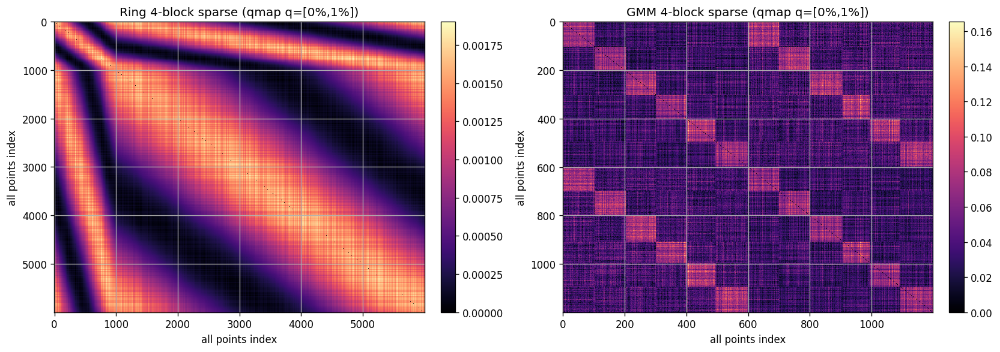

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, A, title in [
    (axes[0], A_ring_sparse_qmap, f"Ring 4-block sparse (qmap q=[{q_low:.0%},{q_high_qmap:.0%}])"),
    (axes[1], A_gmm_sparse_qmap,  f"GMM 4-block sparse (qmap q=[{q_low:.0%},{q_high_qmap:.0%}])"),
]:
    disp = np.maximum(A, 0.0)
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto",
                   vmin=0.0, vmax=float(disp.max()) if disp.size else 1.0)
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## Step 5: Binarize, Symmetrize and Normalize

### kNN

In [13]:
# Cell 1/5: post-process KNN matrix -> binarized, symmetrized, normalized (NO t-SNE)
import numpy as np
import matplotlib.pyplot as plt

def postprocess_matrix(A_sparse):
    A = np.array(A_sparse, copy=True, dtype=float)
    A = (A > 0).astype(float)          # 1) binarize
    A = np.maximum(A, A.T)             # 2) symmetrize
    np.fill_diagonal(A, 0.0)
    s = A.sum()
    if s > 0:
        A /= s                         # 3) normalize
    return A

A_ring_knn_post = postprocess_matrix(A_ring_sparse_knn)
A_gmm_knn_post  = postprocess_matrix(A_gmm_sparse_knn)

print("KNN ring: nnz =", np.count_nonzero(A_ring_knn_post), "sum =", A_ring_knn_post.sum())
print("KNN gmm : nnz =", np.count_nonzero(A_gmm_knn_post),  "sum =", A_gmm_knn_post.sum())






KNN ring: nnz = 986268 sum = 0.9999999999999999
KNN gmm : nnz = 60476 sum = 1.0


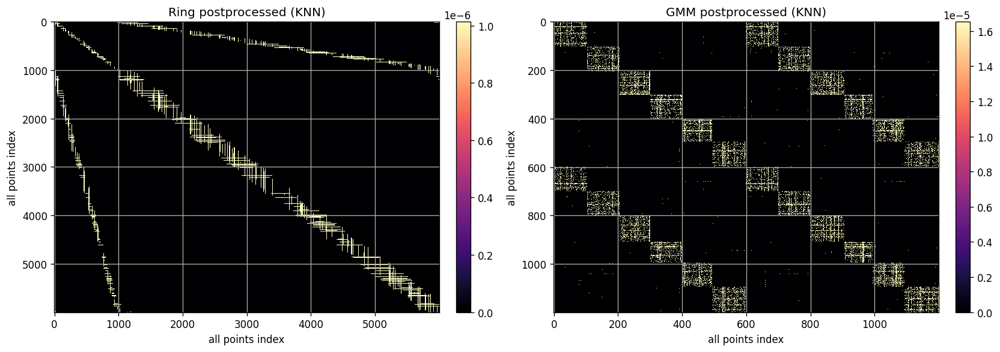

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, A, title in [
    (axes[0], A_ring_knn_post, "Ring postprocessed (KNN)"),
    (axes[1], A_gmm_knn_post,  "GMM postprocessed (KNN)"),
]:
    disp = np.maximum(A, 0.0)
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto",
                   vmin=0.0, vmax=float(disp.max()) if disp.size else 1.0)
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### top percentage of neighbors

Pct-neighbors ring: nnz = 2902684 sum = 0.9999999999999999
Pct-neighbors gmm : nnz = 109064 sum = 1.0000000000000002


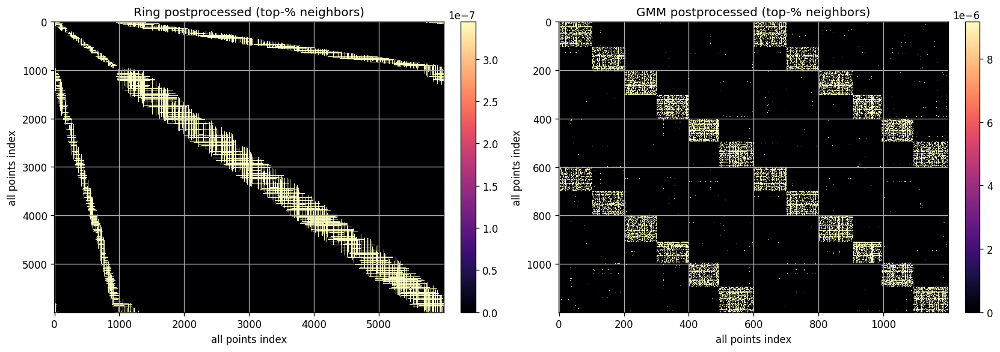

In [27]:
# Cell 2/5: post-process top-%-neighbors matrix (NO t-SNE)
A_ring_pctn_post = postprocess_matrix(A_ring_sparse_pct_neighbors)
A_gmm_pctn_post  = postprocess_matrix(A_gmm_sparse_pct_neighbors)

print("Pct-neighbors ring: nnz =", np.count_nonzero(A_ring_pctn_post), "sum =", A_ring_pctn_post.sum())
print("Pct-neighbors gmm : nnz =", np.count_nonzero(A_gmm_pctn_post),  "sum =", A_gmm_pctn_post.sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, A, title in [
    (axes[0], A_ring_pctn_post, "Ring postprocessed (top-% neighbors)"),
    (axes[1], A_gmm_pctn_post,  "GMM postprocessed (top-% neighbors)"),
]:
    disp = np.maximum(A, 0.0)
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto",
                   vmin=0.0, vmax=float(disp.max()) if disp.size else 1.0)
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


### top percentage of probability mass

Pct-mass ring: nnz = 4963352 sum = 1.0
Pct-mass gmm : nnz = 183590 sum = 1.0


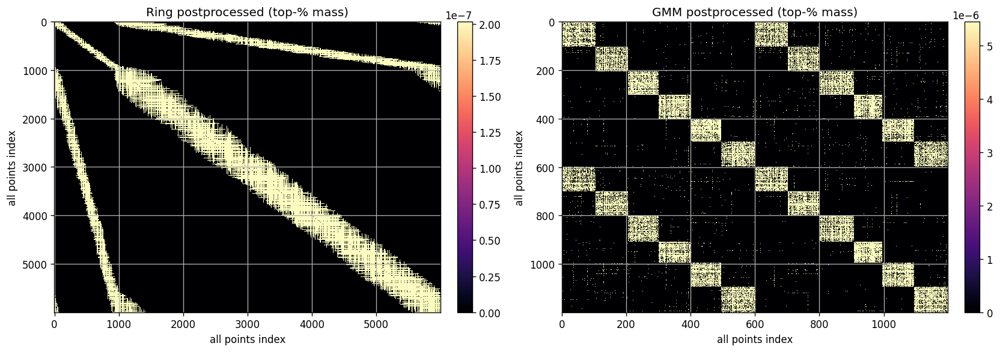

In [28]:
# Cell 3/5: post-process top-%-mass matrix (NO t-SNE)
A_ring_pctm_post = postprocess_matrix(A_ring_sparse_pct_mass)
A_gmm_pctm_post  = postprocess_matrix(A_gmm_sparse_pct_mass)

print("Pct-mass ring: nnz =", np.count_nonzero(A_ring_pctm_post), "sum =", A_ring_pctm_post.sum())
print("Pct-mass gmm : nnz =", np.count_nonzero(A_gmm_pctm_post),  "sum =", A_gmm_pctm_post.sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, A, title in [
    (axes[0], A_ring_pctm_post, "Ring postprocessed (top-% mass)"),
    (axes[1], A_gmm_pctm_post,  "GMM postprocessed (top-% mass)"),
]:
    disp = np.maximum(A, 0.0)
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto",
                   vmin=0.0, vmax=float(disp.max()) if disp.size else 1.0)
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


### values above percentage of top value

Above-top ring: nnz = 11715124 sum = 1.0000000000000002
Above-top gmm : nnz = 1276160 sum = 1.0


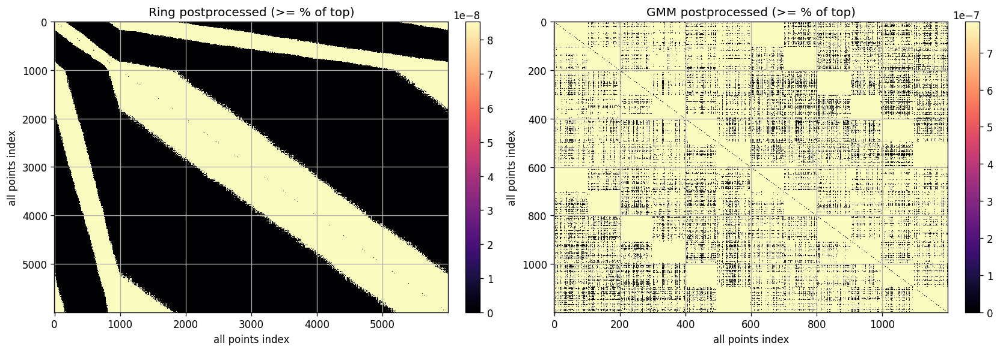

In [29]:
# Cell 4/5: post-process values-above-%-top matrix (NO t-SNE)
A_ring_top_post = postprocess_matrix(A_ring_sparse_above_top)
A_gmm_top_post  = postprocess_matrix(A_gmm_sparse_above_top)

print("Above-top ring: nnz =", np.count_nonzero(A_ring_top_post), "sum =", A_ring_top_post.sum())
print("Above-top gmm : nnz =", np.count_nonzero(A_gmm_top_post),  "sum =", A_gmm_top_post.sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, A, title in [
    (axes[0], A_ring_top_post, "Ring postprocessed (>= % of top)"),
    (axes[1], A_gmm_top_post,  "GMM postprocessed (>= % of top)"),
]:
    disp = np.maximum(A, 0.0)
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto",
                   vmin=0.0, vmax=float(disp.max()) if disp.size else 1.0)
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


### quantile mass-shift mapping


QMap ring: nnz = 7908652 sum = 744.813362894123
QMap gmm : nnz = 308452 sum = 4842.14197588251


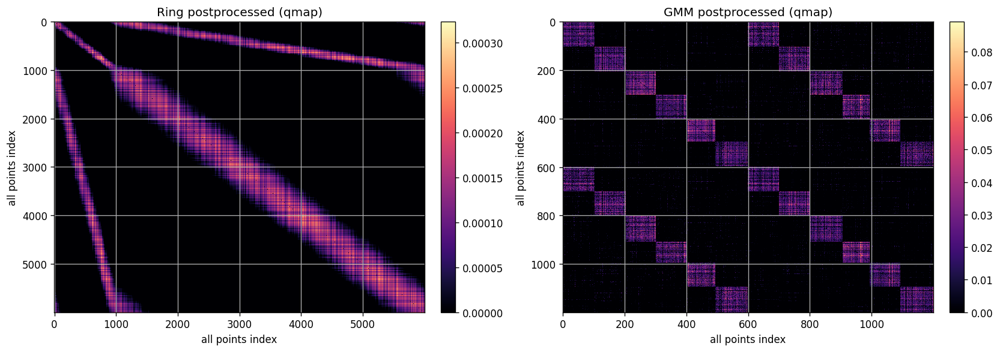

In [15]:
# Cell 5/5: post-process quantile-mapped matrix (NO t-SNE)

A_ring_q_post = A_ring_sparse_qmap
A_gmm_q_post  = A_gmm_sparse_qmap

print("QMap ring: nnz =", np.count_nonzero(A_ring_q_post), "sum =", A_ring_q_post.sum())
print("QMap gmm : nnz =", np.count_nonzero(A_gmm_q_post),  "sum =", A_gmm_q_post.sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, A, title in [
    (axes[0], A_ring_q_post, "Ring postprocessed (qmap)"),
    (axes[1], A_gmm_q_post,  "GMM postprocessed (qmap)"),
]:
    disp = np.maximum(A, 0.0)
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto",
                   vmin=0.0, vmax=float(disp.max()) if disp.size else 1.0)
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## Step 6: compute tSNE embeddings

In [1]:
# Cell 1 — tSNE: test_diag_eot KNN
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from openTSNE import TSNE
from openTSNE.affinity import Affinities

if "run_tsne_from_graph" not in globals():
    def run_tsne_from_graph(G, seed=0, n_epochs=200):
        G = np.asarray(G, dtype=float)
        G = np.nan_to_num(G, nan=0.0, posinf=0.0, neginf=0.0)
        G[G < 0] = 0.0
        np.fill_diagonal(G, 0.0)
        s = G.sum()
        if s <= 0:
            raise ValueError("Graph has zero total mass.")
        G = G / s

        n = G.shape[0]
        init = np.random.RandomState(seed).randn(n, 2) * 1e-4
        n_early = n_epochs // 3
        n_late = n_epochs - n_early

        affinities = Affinities()
        affinities.P = sp.csr_matrix(G)

        embedder = TSNE(
            n_components=2,
            random_state=seed,
            verbose=True,
            early_exaggeration_iter=n_early,
            n_iter=n_late,
        )
        return embedder.fit(affinities=affinities, initialization=init)

if "plot_tsne_pair" not in globals():
    def plot_tsne_pair(emb_ring, emb_gmm, title_ring, title_gmm):
        ring_colors = np.array(["r"] * n0_ring + ["b"] * n1_ring)
        gmm_colors  = np.array(["r"] * gmm_n0 + ["b"] * gmm_n1)

        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        o0 = np.random.permutation(len(ring_colors))
        axes[0].scatter(*emb_ring[o0].T, s=1, c=ring_colors[o0])
        axes[0].set_aspect("equal")
        axes[0].axis("off")
        axes[0].set_title(title_ring)

        o1 = np.random.permutation(len(gmm_colors))
        axes[1].scatter(*emb_gmm[o1].T, s=1, c=gmm_colors[o1])
        axes[1].set_aspect("equal")
        axes[1].axis("off")
        axes[1].set_title(title_gmm)

        plt.tight_layout()
        plt.show()

ring_embd_knn = run_tsne_from_graph(A_ring_sparse_knn, seed=0, n_epochs=200)
gmm_embd_knn  = run_tsne_from_graph(A_gmm_sparse_knn,  seed=0, n_epochs=200)

plot_tsne_pair(
    ring_embd_knn,
    gmm_embd_knn,
    "Ring tSNE (KNN sparsification)",
    "GMM tSNE (KNN sparsification)",
)


NameError: name 'A_ring_sparse_knn' is not defined

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence 2.5037, 50 iterations in 1.6613 sec
   --> Time elapsed: 2.11 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 0.8252, 50 iterations in 1.3926 sec
Iteration  100, KL divergence 0.8235, 50 iterations in 1.3505 sec
   --> Time elapsed: 3.62 seconds
--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggera

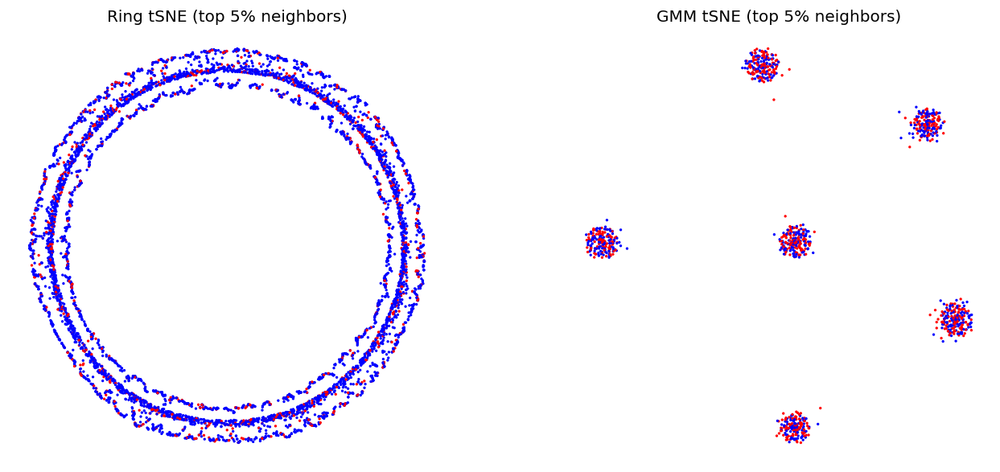

In [ ]:
# Cell 2 — tSNE: top percentage neighbors
ring_embd_pct_neighbors = run_tsne_from_graph(A_ring_sparse_pct_neighbors, seed=0, n_epochs=200)
gmm_embd_pct_neighbors  = run_tsne_from_graph(A_gmm_sparse_pct_neighbors,  seed=0, n_epochs=200)

plot_tsne_pair(
    ring_embd_pct_neighbors,
    gmm_embd_pct_neighbors,
    f"Ring tSNE (top {p_neighbors:.0%} neighbors)",
    f"GMM tSNE (top {p_neighbors:.0%} neighbors)",
)


--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence 1.9812, 50 iterations in 2.0579 sec
   --> Time elapsed: 2.66 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 0.5805, 50 iterations in 1.9063 sec
Iteration  100, KL divergence 0.5623, 50 iterations in 1.8687 sec
   --> Time elapsed: 5.00 seconds
--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggera

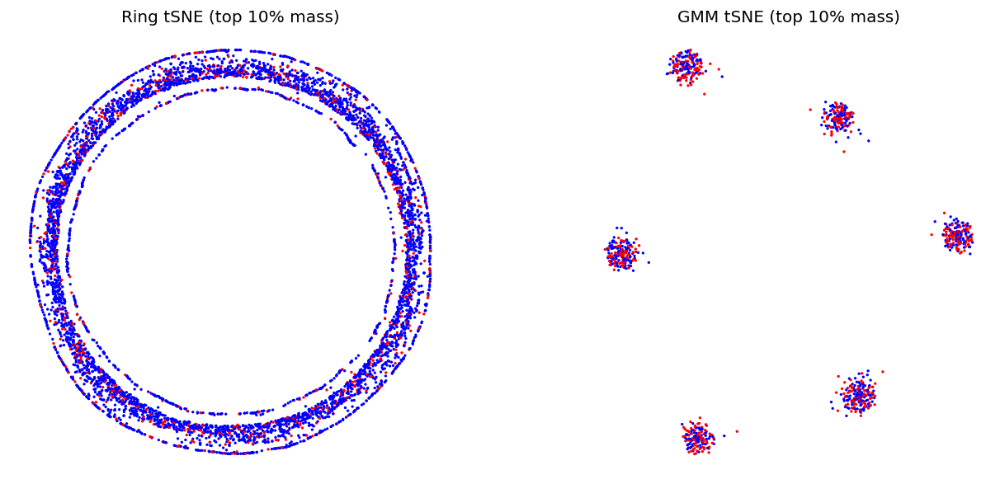

In [ ]:
# Cell 3 — tSNE: top percentage mass
ring_embd_pct_mass = run_tsne_from_graph(A_ring_sparse_pct_mass, seed=0, n_epochs=200)
gmm_embd_pct_mass  = run_tsne_from_graph(A_gmm_sparse_pct_mass,  seed=0, n_epochs=200)

plot_tsne_pair(
    ring_embd_pct_mass,
    gmm_embd_pct_mass,
    f"Ring tSNE (top {p_mass:.0%} mass)",
    f"GMM tSNE (top {p_mass:.0%} mass)",
)


--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence -1.0742, 50 iterations in 3.5647 sec
   --> Time elapsed: 4.46 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 0.4223, 50 iterations in 3.5242 sec
Iteration  100, KL divergence 0.4180, 50 iterations in 3.4239 sec
   --> Time elapsed: 9.16 seconds
--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exagger

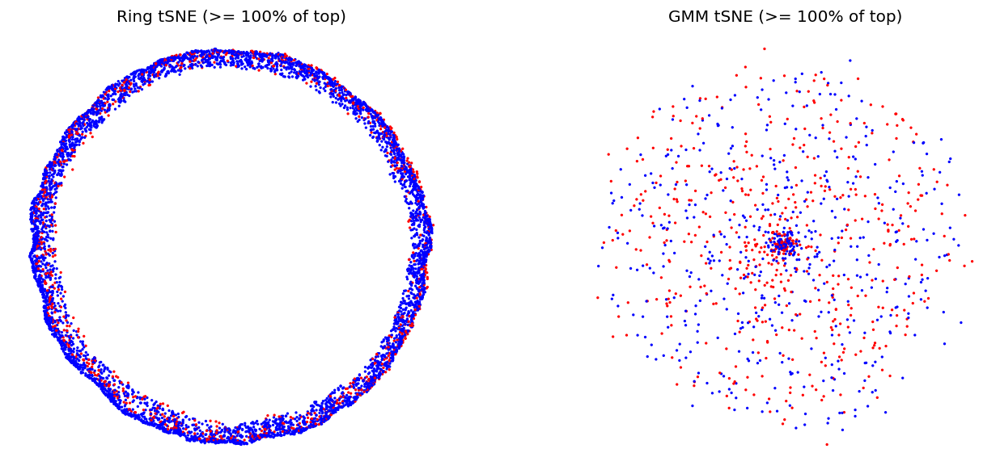

In [ ]:
# Cell 4 — tSNE: values above percentage of top
ring_embd_above_top = run_tsne_from_graph(A_ring_sparse_above_top, seed=0, n_epochs=200)
gmm_embd_above_top  = run_tsne_from_graph(A_gmm_sparse_above_top,  seed=0, n_epochs=200)

plot_tsne_pair(
    ring_embd_above_top,
    gmm_embd_above_top,
    f"Ring tSNE (>= {p_top:.0%} of top)",
    f"GMM tSNE (>= {p_top:.0%} of top)",
)


--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence 1.7355, 50 iterations in 2.8572 sec
   --> Time elapsed: 3.67 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 0.3471, 50 iterations in 2.7118 sec
Iteration  100, KL divergence 0.3241, 50 iterations in 2.6680 sec
   --> Time elapsed: 7.06 seconds
--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggera

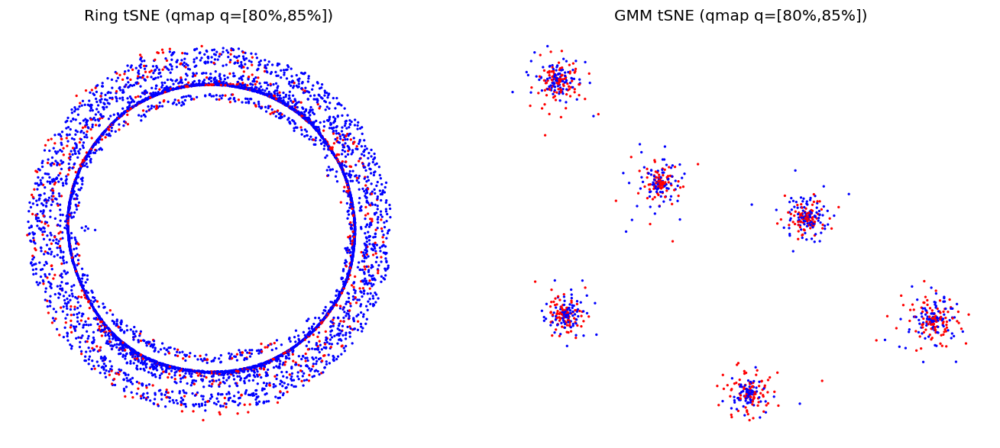

In [ ]:
# Cell 5 — tSNE: quantile mapping

ring_embd_qmap = run_tsne_from_graph(A_ring_sparse_qmap, seed=0, n_epochs=200)
gmm_embd_qmap  = run_tsne_from_graph(A_gmm_sparse_qmap,  seed=0, n_epochs=200)

plot_tsne_pair(
    ring_embd_qmap,
    gmm_embd_qmap,
    f"Ring tSNE (qmap q=[{q_low:.0%},{q_high_qmap:.0%}])",
    f"GMM tSNE (qmap q=[{q_low:.0%},{q_high_qmap:.0%}])",
)


### Value Sweep for Methods

[kNN] value=5 ...
[kNN] value=10 ...
[kNN] value=15 ...
[kNN] value=20 ...
[kNN] value=25 ...
[kNN] value=50 ...


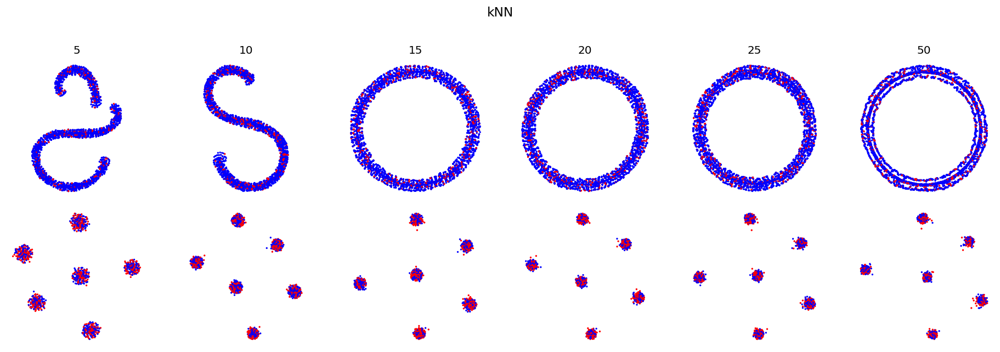

[Top % Neighbors] value=1 ...
[Top % Neighbors] value=5 ...
[Top % Neighbors] value=10 ...
[Top % Neighbors] value=20 ...
[Top % Neighbors] value=30 ...
[Top % Neighbors] value=50 ...
[Top % Neighbors] value=75 ...
[Top % Neighbors] value=90 ...
[Top % Neighbors] value=100 ...


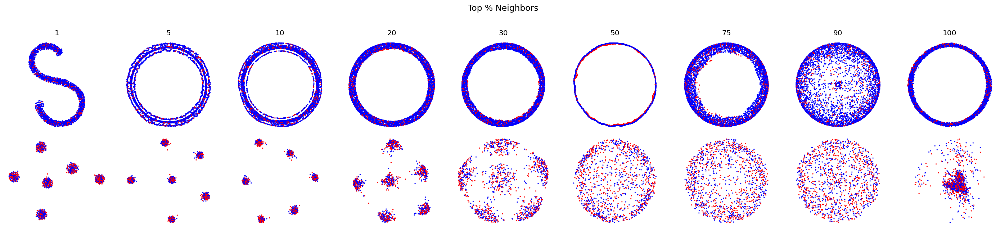

[Top % Mass] value=1 ...
[Top % Mass] value=5 ...
[Top % Mass] value=10 ...
[Top % Mass] value=20 ...
[Top % Mass] value=30 ...
[Top % Mass] value=50 ...
[Top % Mass] value=75 ...
[Top % Mass] value=90 ...
[Top % Mass] value=100 ...


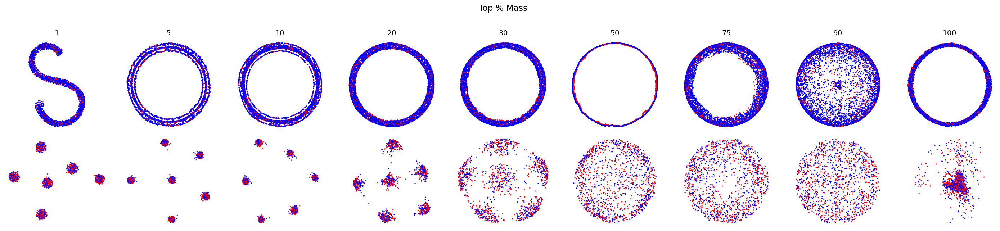

[Top Value Threshold] value=0.99995 ...
[Top Value Threshold] value=0.9999 ...
[Top Value Threshold] value=0.9995 ...
[Top Value Threshold] value=0.999 ...
[Top Value Threshold] value=0.995 ...
[Top Value Threshold] value=0.99 ...


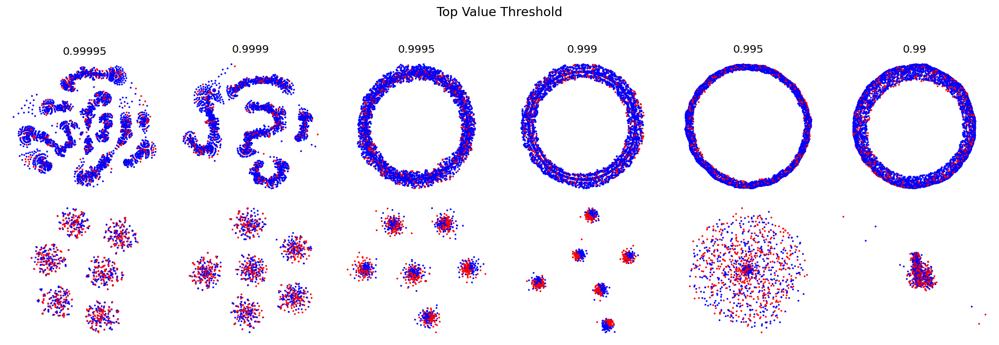

In [ ]:
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from openTSNE import TSNE
from openTSNE.affinity import Affinities

from sparsification import (
    sparsify_test_diag_eot_knn,
    sparsify_top_percentage_neighbors,
    sparsify_top_percentage_mass,
    sparsify_values_above_percentage_top,
)

# -----------------------------
# Parameter grids
# -----------------------------
k_values = [5, 10, 15, 20, 25, 50]
pct_values = [1, 5, 10, 20, 30, 50, 75, 90, 100]   # interpreted as %
top_values = [0.99995, 0.99990, 0.9995, 0.999, 0.995, 0.99]

# -----------------------------
# tSNE helper
# -----------------------------
def run_tsne_from_graph(G, seed=0, n_epochs=200):
    G = np.asarray(G, dtype=float)
    G = np.nan_to_num(G, nan=0.0, posinf=0.0, neginf=0.0)
    G[G < 0] = 0.0
    np.fill_diagonal(G, 0.0)
    s = G.sum()
    if s <= 0:
        raise ValueError("Graph has zero total mass; cannot run tSNE.")
    G = G / s

    n = G.shape[0]
    init = np.random.RandomState(seed).randn(n, 2) * 1e-4
    n_early = n_epochs // 3
    n_late = n_epochs - n_early

    affinities = Affinities()
    affinities.P = sp.csr_matrix(G)

    embedder = TSNE(
        n_components=2,
        random_state=seed,
        verbose=False,
        early_exaggeration_iter=n_early,
        n_iter=n_late,
    )
    return embedder.fit(affinities=affinities, initialization=init)

# -----------------------------
# Plot helper
# -----------------------------
def plot_embedding_grid(embeddings, values, method_name):
    ring_colors = np.array(["r"] * n0_ring + ["b"] * n1_ring)
    gmm_colors  = np.array(["r"] * gmm_n0 + ["b"] * gmm_n1)

    ncols = len(values)
    fig, axes = plt.subplots(2, ncols, figsize=(2.6 * ncols, 5.2), squeeze=False)

    for j, v in enumerate(values):
        emb_ring = embeddings[v]["ring"]
        emb_gmm = embeddings[v]["gmm"]

        o0 = np.random.permutation(len(ring_colors))
        ax0 = axes[0, j]
        ax0.scatter(*emb_ring[o0].T, s=1, c=ring_colors[o0])
        ax0.set_aspect("equal")
        ax0.axis("off")
        ax0.set_title(f"{v}")

        o1 = np.random.permutation(len(gmm_colors))
        ax1 = axes[1, j]
        ax1.scatter(*emb_gmm[o1].T, s=1, c=gmm_colors[o1])
        ax1.set_aspect("equal")
        ax1.axis("off")

    axes[0, 0].set_ylabel("Ring", fontsize=11)
    axes[1, 0].set_ylabel("GMM", fontsize=11)
    fig.suptitle(method_name, fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

# -----------------------------
# Runner for one method
# -----------------------------
def run_method_grid(values, build_sparse_graphs_fn, method_name, seed=0, n_epochs=200):
    out = {}
    for v in values:
        print(f"[{method_name}] value={v} ...")
        G_ring, G_gmm = build_sparse_graphs_fn(v)
        emb_ring = run_tsne_from_graph(G_ring, seed=seed, n_epochs=n_epochs)
        emb_gmm  = run_tsne_from_graph(G_gmm,  seed=seed, n_epochs=n_epochs)
        out[v] = {"ring": emb_ring, "gmm": emb_gmm}
    plot_embedding_grid(out, values, method_name)
    return out

# -----------------------------
# Build functions per method
# -----------------------------
def build_knn(k):
    ring = sparsify_test_diag_eot_knn(
        A_ring, n0=n0_ring, n1=n1_ring, k=int(k), scale_cross_by_ratio=True
    ).matrix
    gmm = sparsify_test_diag_eot_knn(
        A_gmm, n0=gmm_n0, n1=gmm_n1, k=int(k), scale_cross_by_ratio=True
    ).matrix
    return ring, gmm

def build_pct_neighbors(pct):
    p = float(pct) / 100.0
    ring = sparsify_top_percentage_neighbors(A_ring, percentage=p, n0=n0_ring, n1=n1_ring, ensure_nonempty=True).matrix
    gmm  = sparsify_top_percentage_neighbors(A_gmm,  percentage=p, n0=gmm_n0, n1=gmm_n1, ensure_nonempty=True).matrix
    return ring, gmm

def build_pct_mass(pct):
    p = float(pct) / 100.0
    ring = sparsify_top_percentage_mass(A_ring, percentage=p, n0=n0_ring, n1=n1_ring, ensure_nonempty=True).matrix
    gmm  = sparsify_top_percentage_mass(A_gmm,  percentage=p, n0=gmm_n0, n1=gmm_n1, ensure_nonempty=True).matrix
    return ring, gmm

def build_top_value(p):
    ring = sparsify_values_above_percentage_top(A_ring, percentage=float(p), n0=n0_ring, n1=n1_ring, ensure_nonempty=True).matrix
    gmm  = sparsify_values_above_percentage_top(A_gmm,  percentage=float(p), n0=gmm_n0, n1=gmm_n1, ensure_nonempty=True).matrix
    return ring, gmm

# -----------------------------
# Run all requested grids
# -----------------------------
# Warning: this is computationally heavy.
# Reduce n_epochs (e.g. 100) if needed.
emb_knn = run_method_grid(k_values, build_knn, "kNN", seed=0, n_epochs=200)
emb_pct_neighbors = run_method_grid(pct_values, build_pct_neighbors, "Top % Neighbors", seed=0, n_epochs=200)
emb_pct_mass = run_method_grid(pct_values, build_pct_mass, "Top % Mass", seed=0, n_epochs=200)
emb_top_value = run_method_grid(top_values, build_top_value, "Top Value Threshold", seed=0, n_epochs=200)


In [ ]:
# -----------------------------
# Quantile-mapping grid
# -----------------------------
from sparsification import quantile_mapping_diag_blocks

# Define the sweep here.
q_low_values = [0.05, 0.10, 0.25, 0.50, 0.75, 0.85, 0.90, 0.95, 0.99]
q_high_values = [0.50, 0.75, 0.90, 0.95, 0.99, 0.995]
include_offdiag = True

def valid_quantile_pairs(q_low_values, q_high_values):
    pairs = []
    for q_low in q_low_values:
        for q_high in q_high_values:
            q_low = float(q_low)
            q_high = float(q_high)
            if q_low < q_high:
                pairs.append((q_low, q_high))
    return pairs

quantile_pairs = valid_quantile_pairs(q_low_values, q_high_values)

if not quantile_pairs:
    raise ValueError("No valid quantile pairs found. Make sure q_low < q_high for at least one combination.")

def plot_quantile_mapping_grid(embeddings, quantile_pairs, method_name):
    ring_colors = np.array(["r"] * n0_ring + ["b"] * n1_ring)
    gmm_colors  = np.array(["r"] * gmm_n0 + ["b"] * gmm_n1)

    ncols = len(quantile_pairs)
    fig, axes = plt.subplots(2, ncols, figsize=(2.8 * ncols, 5.8), squeeze=False)

    for j, pair in enumerate(quantile_pairs):
        emb_ring = embeddings[pair]["ring"]
        emb_gmm = embeddings[pair]["gmm"]
        q_low, q_high = pair

        o0 = np.random.permutation(len(ring_colors))
        ax0 = axes[0, j]
        ax0.scatter(*emb_ring[o0].T, s=1, c=ring_colors[o0])
        ax0.set_aspect("equal")
        ax0.axis("off")
        ax0.set_title(f"low={q_low:.0%}\nhigh={q_high:.0%}")

        o1 = np.random.permutation(len(gmm_colors))
        ax1 = axes[1, j]
        ax1.scatter(*emb_gmm[o1].T, s=1, c=gmm_colors[o1])
        ax1.set_aspect("equal")
        ax1.axis("off")

    axes[0, 0].set_ylabel("Ring", fontsize=11)
    axes[1, 0].set_ylabel("GMM", fontsize=11)
    fig.suptitle(method_name, fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

def build_quantile_mapping_graphs(q_low, q_high, include_offdiag=True):
    ring = quantile_mapping_diag_blocks(
        A_ring,
        n0=n0_ring,
        q_low=float(q_low),
        q_high=float(q_high),
        include_offdiag=include_offdiag,
    ).matrix
    gmm = quantile_mapping_diag_blocks(
        A_gmm,
        n0=gmm_n0,
        q_low=float(q_low),
        q_high=float(q_high),
        include_offdiag=include_offdiag,
    ).matrix
    return ring, gmm

def run_quantile_mapping_grid(quantile_pairs, seed=0, n_epochs=200, include_offdiag=True):
    out = {}
    for q_low, q_high in quantile_pairs:
        print(f"[Quantile Mapping] q_low={q_low:.0%}, q_high={q_high:.0%} ...")
        G_ring, G_gmm = build_quantile_mapping_graphs(q_low, q_high, include_offdiag=include_offdiag)
        emb_ring = run_tsne_from_graph(G_ring, seed=seed, n_epochs=n_epochs)
        emb_gmm  = run_tsne_from_graph(G_gmm,  seed=seed, n_epochs=n_epochs)
        out[(q_low, q_high)] = {"ring": emb_ring, "gmm": emb_gmm}
    plot_quantile_mapping_grid(out, quantile_pairs, f"Quantile Mapping (include_offdiag={include_offdiag})")
    return out

# Warning: every valid (q_low, q_high) combination is evaluated.
emb_quantile_mapping = run_quantile_mapping_grid(
    quantile_pairs,
    seed=0,
    n_epochs=200,
    include_offdiag=include_offdiag,
)


ModuleNotFoundError: No module named 'sparsification'

### Benchmarking

The standalone benchmarking workflow now lives in `benchmarking.ipynb`.


### Sparsify OT plan

## Alternate Step 3: Sparsify OT Plans


In [9]:
from matplotlib.colors import LogNorm
from ne_aligned_utils.toy_utils import get_diag_graph
from ne_aligned_utils.transport_plan_sparsify import (
    sparsify_plan_percentage_neighbors,
    sparsify_plan_percentage_mass,
)


def build_four_block_matrix_from_plan(P):
    return get_diag_graph(P)


def _alt_binarized_plot_matrix(A, P_sparse, diag_threshold=0.0):
    A = np.array(A, copy=True, dtype=float)
    n0, n1 = P_sparse.shape

    A00 = A[:n0, :n0]
    A11 = A[n0:, n0:]
    if diag_threshold > 0.0:
        if A00.size and A00.max() > 0:
            A00 = np.where(A00 >= diag_threshold * A00.max(), A00, 0.0)
        if A11.size and A11.max() > 0:
            A11 = np.where(A11 >= diag_threshold * A11.max(), A11, 0.0)

    B = np.zeros_like(A, dtype=float)
    B[:n0, :n0] = (A00 > 0).astype(float)
    B[n0:, n0:] = (A11 > 0).astype(float)

    support = (np.asarray(P_sparse) > 0).astype(float)
    B[:n0, n0:] = support
    B[n0:, :n0] = support.T
    return B


def _alt_plot_pair(M_ring, M_gmm, title_ring, title_gmm, xlabel, ylabel, *, use_lognorm=False, suptitle=None):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax, M, title in [
        (axes[0], M_ring, title_ring),
        (axes[1], M_gmm, title_gmm),
    ]:
        if use_lognorm:
            vals = M[M > 0]
            norm = None
            if vals.size > 0:
                vmin = max(float(np.quantile(vals, 0.01)), 1e-16)
                vmax = float(np.quantile(vals, 0.995))
                if vmax <= vmin:
                    vmax = float(vals.max()) if float(vals.max()) > vmin else vmin * 10.0
                norm = LogNorm(vmin=vmin, vmax=vmax)
            disp = np.array(M, copy=True)
            disp[disp <= 0] = np.nan
            im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto", norm=norm)
        else:
            disp = np.maximum(M, 0.0)
            im = ax.imshow(
                disp,
                cmap="magma",
                interpolation="nearest",
                aspect="auto",
                vmin=0.0,
                vmax=float(disp.max()) if disp.size else 1.0,
            )

        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    if suptitle is not None:
        fig.suptitle(suptitle)
    fig.tight_layout()
    plt.show()


def sparsify_plan_values_above_percentage_top(
    P,
    percentage,
    ensure_nonempty=True,
    renormalize=True,
    return_stats=False,
):
    P = np.asarray(P, dtype=float)
    if P.ndim != 2:
        raise ValueError(f"P must be 2D, got shape {P.shape}.")
    if P.shape[0] == 0 or P.shape[1] == 0:
        raise ValueError("P must have non-zero dimensions.")
    if np.any(P < 0):
        raise ValueError("P must be non-negative.")

    p = float(percentage)
    if not (0.0 < p <= 1.0):
        raise ValueError(f"percentage must be in (0, 1], got {percentage}.")

    row_max = P.max(axis=1, keepdims=True)
    col_max = P.max(axis=0, keepdims=True)
    mask = (P >= p * row_max) | (P >= p * col_max)

    if ensure_nonempty:
        empty_rows = np.where(~mask.any(axis=1))[0]
        if empty_rows.size > 0:
            row_argmax = np.argmax(P[empty_rows], axis=1)
            mask[empty_rows, row_argmax] = True

        empty_cols = np.where(~mask.any(axis=0))[0]
        if empty_cols.size > 0:
            col_argmax = np.argmax(P[:, empty_cols], axis=0)
            mask[col_argmax, empty_cols] = True

    P_sparse = np.where(mask, P, 0.0)
    retained_mass_before_renorm = float(P_sparse.sum())

    if renormalize:
        if retained_mass_before_renorm <= 0:
            raise ValueError("Sparsification produced zero retained mass; cannot renormalize.")
        P_sparse = P_sparse / retained_mass_before_renorm

    stats = {
        "method": "values_above_percentage_top",
        "shape": tuple(P.shape),
        "nnz": int(np.count_nonzero(P_sparse)),
        "density": float(np.count_nonzero(P_sparse) / P_sparse.size),
        "sum": float(P_sparse.sum()),
        "retained_mass_before_renorm": retained_mass_before_renorm,
        "percentage": float(p),
    }

    if return_stats:
        return P_sparse, stats
    return P_sparse


### top percentage of neighbors


In [10]:
alt_p_neighbors = 0.05

P_ring_alt_pct_neighbors, ring_alt_pct_neighbors_stats = sparsify_plan_percentage_neighbors(
    P_ring,
    percentage=alt_p_neighbors,
    ensure_nonempty=True,
    renormalize=False,
    return_stats=True,
)
P_gmm_alt_pct_neighbors, gmm_alt_pct_neighbors_stats = sparsify_plan_percentage_neighbors(
    P_gmm,
    percentage=alt_p_neighbors,
    ensure_nonempty=True,
    renormalize=False,
    return_stats=True,
)

print("Ring sparse OT plan stats (top-% neighbors):", ring_alt_pct_neighbors_stats)
print("GMM  sparse OT plan stats (top-% neighbors):", gmm_alt_pct_neighbors_stats)


Ring sparse OT plan stats (top-% neighbors): {'nnz': 403141, 'density': 0.0806282, 'retained_mass_before_renorm': 0.08138098024356705, 'method': 'percentage_neighbors', 'percentage': 0.05}
GMM  sparse OT plan stats (top-% neighbors): {'nnz': 26594, 'density': 0.07387222222222223, 'retained_mass_before_renorm': 0.07408213658183131, 'method': 'percentage_neighbors', 'percentage': 0.05}


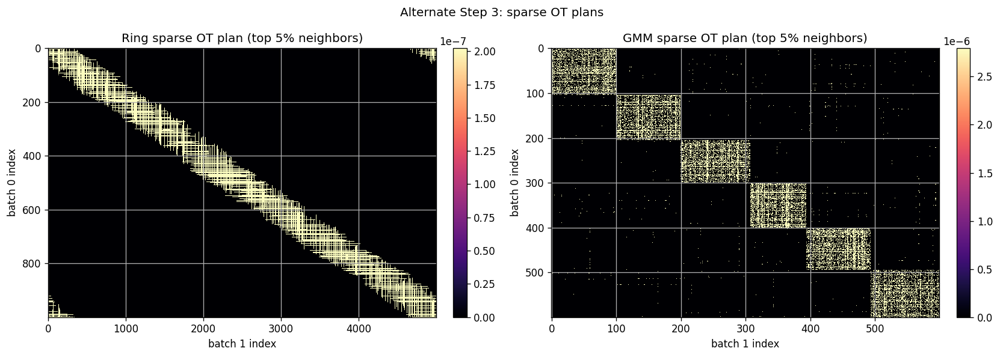

In [11]:
_alt_plot_pair(
    P_ring_alt_pct_neighbors,
    P_gmm_alt_pct_neighbors,
    f"Ring sparse OT plan (top {alt_p_neighbors:.0%} neighbors)",
    f"GMM sparse OT plan (top {alt_p_neighbors:.0%} neighbors)",
    xlabel="batch 1 index",
    ylabel="batch 0 index",
    use_lognorm=False,
    suptitle="Alternate Step 3: sparse OT plans",
)


### top percentage of probability mass


In [76]:
alt_p_mass = 0.10

P_ring_alt_pct_mass, ring_alt_pct_mass_stats = sparsify_plan_percentage_mass(
    P_ring,
    percentage=alt_p_mass,
    ensure_nonempty=True,
    renormalize=True,
    return_stats=True,
)
P_gmm_alt_pct_mass, gmm_alt_pct_mass_stats = sparsify_plan_percentage_mass(
    P_gmm,
    percentage=alt_p_mass,
    ensure_nonempty=True,
    renormalize=True,
    return_stats=True,
)

print("Ring sparse OT plan stats (top-% mass):", ring_alt_pct_mass_stats)
print("GMM  sparse OT plan stats (top-% mass):", gmm_alt_pct_mass_stats)


Ring sparse OT plan stats (top-% mass): {'nnz': 497178, 'density': 0.0994356, 'retained_mass_before_renorm': 0.10034333576920304, 'method': 'percentage_mass', 'percentage': 0.1}
GMM  sparse OT plan stats (top-% mass): {'nnz': 36000, 'density': 0.1, 'retained_mass_before_renorm': 0.10026221365092139, 'method': 'percentage_mass', 'percentage': 0.1}


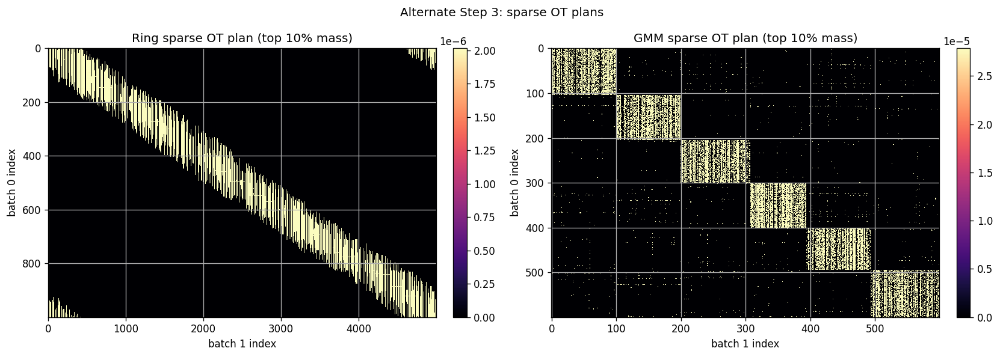

In [77]:
_alt_plot_pair(
    P_ring_alt_pct_mass,
    P_gmm_alt_pct_mass,
    f"Ring sparse OT plan (top {alt_p_mass:.0%} mass)",
    f"GMM sparse OT plan (top {alt_p_mass:.0%} mass)",
    xlabel="batch 1 index",
    ylabel="batch 0 index",
    use_lognorm=False,
    suptitle="Alternate Step 3: sparse OT plans",
)


### values above percentage of top value


In [78]:
alt_p_top = 0.999

P_ring_alt_above_top, ring_alt_above_top_stats = sparsify_plan_values_above_percentage_top(
    P_ring,
    percentage=alt_p_top,
    ensure_nonempty=True,
    renormalize=True,
    return_stats=True,
)
P_gmm_alt_above_top, gmm_alt_above_top_stats = sparsify_plan_values_above_percentage_top(
    P_gmm,
    percentage=alt_p_top,
    ensure_nonempty=True,
    renormalize=True,
    return_stats=True,
)

print("Ring sparse OT plan stats (>= % of top):", ring_alt_above_top_stats)
print("GMM  sparse OT plan stats (>= % of top):", gmm_alt_above_top_stats)


Ring sparse OT plan stats (>= % of top): {'method': 'values_above_percentage_top', 'shape': (1000, 5000), 'nnz': 372690, 'density': 0.074538, 'sum': 1.0, 'retained_mass_before_renorm': 0.07523310750042264, 'percentage': 0.999}
GMM  sparse OT plan stats (>= % of top): {'method': 'values_above_percentage_top', 'shape': (600, 600), 'nnz': 15947, 'density': 0.044297222222222224, 'sum': 1.0, 'retained_mass_before_renorm': 0.04442811197985313, 'percentage': 0.999}


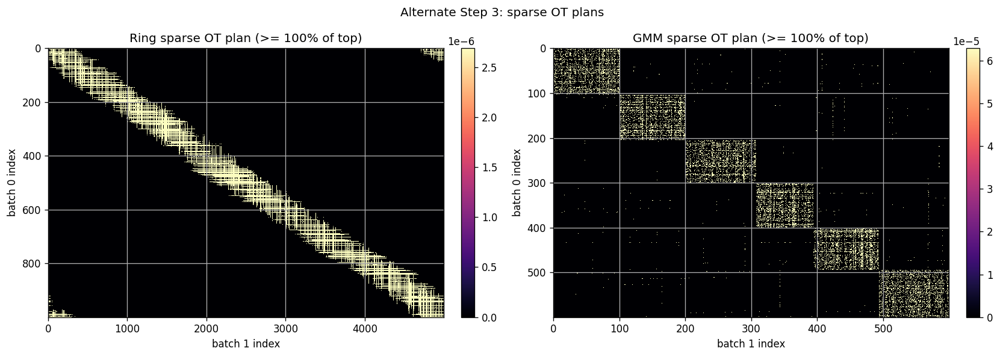

In [79]:
_alt_plot_pair(
    P_ring_alt_above_top,
    P_gmm_alt_above_top,
    f"Ring sparse OT plan (>= {alt_p_top:.0%} of top)",
    f"GMM sparse OT plan (>= {alt_p_top:.0%} of top)",
    xlabel="batch 1 index",
    ylabel="batch 0 index",
    use_lognorm=False,
    suptitle="Alternate Step 3: sparse OT plans",
)


## Alternate Step 4: Build 4-block Matrices from Sparse OT Plans


### top percentage of neighbors


In [22]:
A_ring_alt_pct_neighbors = build_four_block_matrix_from_plan(P_ring_alt_pct_neighbors)
A_gmm_alt_pct_neighbors = build_four_block_matrix_from_plan(P_gmm_alt_pct_neighbors)

print(f"A_ring_alt_pct_neighbors shape={A_ring_alt_pct_neighbors.shape}, sum={A_ring_alt_pct_neighbors.sum():.6f}")
print(f"A_gmm_alt_pct_neighbors  shape={A_gmm_alt_pct_neighbors.shape}, sum={A_gmm_alt_pct_neighbors.sum():.6f}")


A_ring_alt_pct_neighbors shape=(6000, 6000), sum=0.655276
A_gmm_alt_pct_neighbors  shape=(1200, 1200), sum=0.302954


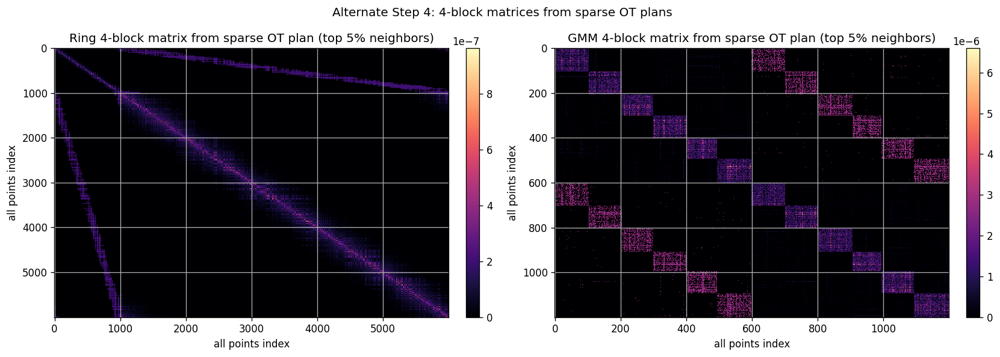

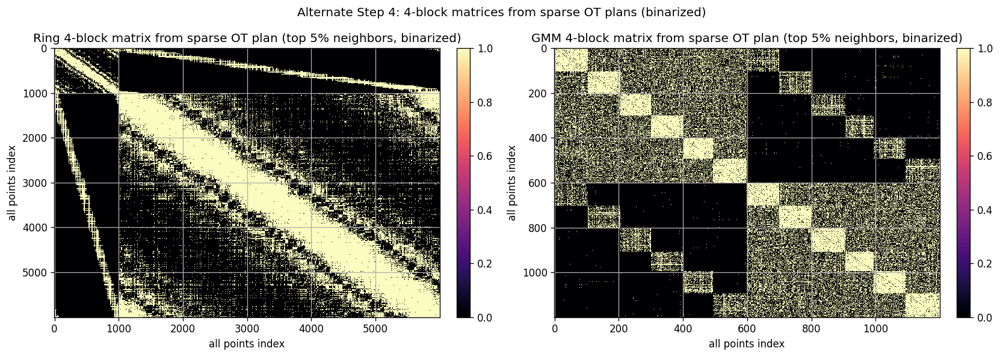

In [23]:
_alt_plot_pair(
    A_ring_alt_pct_neighbors,
    A_gmm_alt_pct_neighbors,
    f"Ring 4-block matrix from sparse OT plan (top {alt_p_neighbors:.0%} neighbors)",
    f"GMM 4-block matrix from sparse OT plan (top {alt_p_neighbors:.0%} neighbors)",
    xlabel="all points index",
    ylabel="all points index",
    use_lognorm=False,
    suptitle="Alternate Step 4: 4-block matrices from sparse OT plans",
)

_alt_plot_pair(
    _alt_binarized_plot_matrix(A_ring_alt_pct_neighbors, P_ring_alt_pct_neighbors, diag_threshold=0.001),
    _alt_binarized_plot_matrix(A_gmm_alt_pct_neighbors, P_gmm_alt_pct_neighbors, diag_threshold=0.001),
    f"Ring 4-block matrix from sparse OT plan (top {alt_p_neighbors:.0%} neighbors, binarized)",
    f"GMM 4-block matrix from sparse OT plan (top {alt_p_neighbors:.0%} neighbors, binarized)",
    xlabel="all points index",
    ylabel="all points index",
    use_lognorm=False,
    suptitle="Alternate Step 4: 4-block matrices from sparse OT plans (binarized)",
)

### top percentage of probability mass


In [94]:
A_ring_alt_pct_mass = build_four_block_matrix_from_plan(P_ring_alt_pct_mass)
A_gmm_alt_pct_mass = build_four_block_matrix_from_plan(P_gmm_alt_pct_mass)

print(f"A_ring_alt_pct_mass shape={A_ring_alt_pct_mass.shape}, sum={A_ring_alt_pct_mass.sum():.6f}")
print(f"A_gmm_alt_pct_mass  shape={A_gmm_alt_pct_mass.shape}, sum={A_gmm_alt_pct_mass.sum():.6f}")


A_ring_alt_pct_mass shape=(6000, 6000), sum=7.129933
A_gmm_alt_pct_mass  shape=(1200, 1200), sum=4.115276


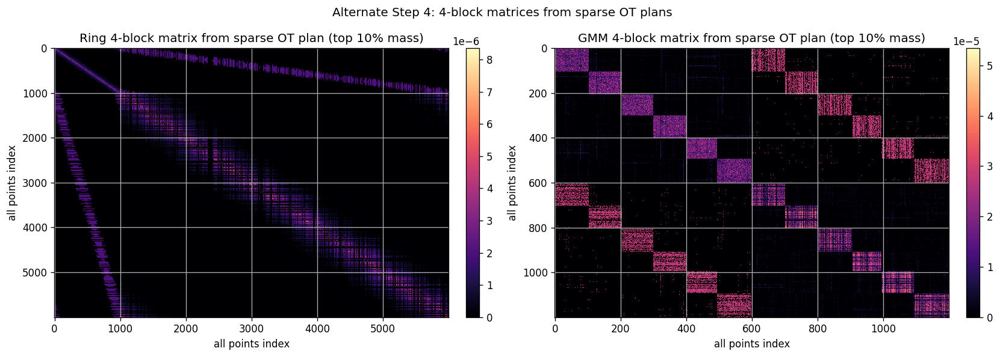

In [95]:
_alt_plot_pair(
    A_ring_alt_pct_mass,
    A_gmm_alt_pct_mass,
    f"Ring 4-block matrix from sparse OT plan (top {alt_p_mass:.0%} mass)",
    f"GMM 4-block matrix from sparse OT plan (top {alt_p_mass:.0%} mass)",
    xlabel="all points index",
    ylabel="all points index",
    use_lognorm=False,
    suptitle="Alternate Step 4: 4-block matrices from sparse OT plans",
)

_alt_plot_pair(
    _alt_binarized_plot_matrix(A_ring_alt_pct_mass, P_ring_alt_pct_mass, diag_threshold=0.001),
    _alt_binarized_plot_matrix(A_gmm_alt_pct_mass, P_gmm_alt_pct_mass, diag_threshold=0.001),
    f"Ring 4-block matrix from sparse OT plan (top {alt_p_mass:.0%} mass, binarized)",
    f"GMM 4-block matrix from sparse OT plan (top {alt_p_mass:.0%} mass, binarized)",
    xlabel="all points index",
    ylabel="all points index",
    use_lognorm=False,
    suptitle="Alternate Step 4: 4-block matrices from sparse OT plans (binarized)",
)


### values above percentage of top value


In [84]:
A_ring_alt_above_top = build_four_block_matrix_from_plan(P_ring_alt_above_top)
A_gmm_alt_above_top = build_four_block_matrix_from_plan(P_gmm_alt_above_top)

print(f"A_ring_alt_above_top shape={A_ring_alt_above_top.shape}, sum={A_ring_alt_above_top.sum():.6f}")
print(f"A_gmm_alt_above_top  shape={A_gmm_alt_above_top.shape}, sum={A_gmm_alt_above_top.sum():.6f}")


A_ring_alt_above_top shape=(6000, 6000), sum=8.086985
A_gmm_alt_above_top  shape=(1200, 1200), sum=4.209966


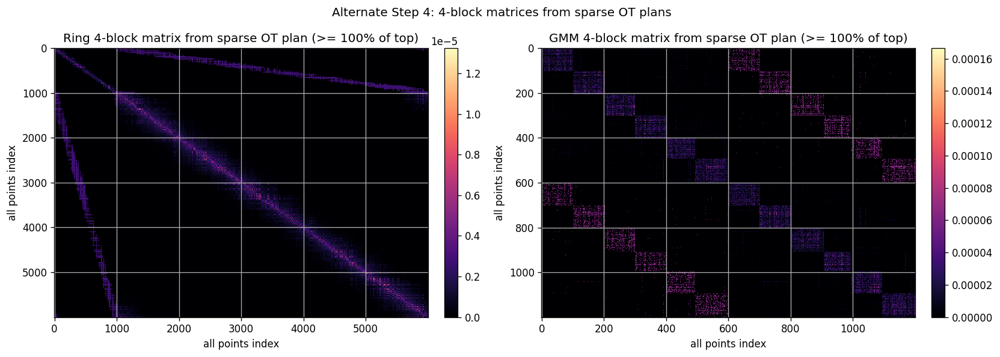

In [85]:
_alt_plot_pair(
    A_ring_alt_above_top,
    A_gmm_alt_above_top,
    f"Ring 4-block matrix from sparse OT plan (>= {alt_p_top:.0%} of top)",
    f"GMM 4-block matrix from sparse OT plan (>= {alt_p_top:.0%} of top)",
    xlabel="all points index",
    ylabel="all points index",
    use_lognorm=False,
    suptitle="Alternate Step 4: 4-block matrices from sparse OT plans",
)

_alt_plot_pair(
    _alt_binarized_plot_matrix(A_ring_alt_above_top, P_ring_alt_above_top, diag_threshold=0.001),
    _alt_binarized_plot_matrix(A_gmm_alt_above_top, P_gmm_alt_above_top, diag_threshold=0.001),
    f"Ring 4-block matrix from sparse OT plan (>= {alt_p_top:.0%} of top, binarized)",
    f"GMM 4-block matrix from sparse OT plan (>= {alt_p_top:.0%} of top, binarized)",
    xlabel="all points index",
    ylabel="all points index",
    use_lognorm=False,
    suptitle="Alternate Step 4: 4-block matrices from sparse OT plans (binarized)",
)


## Alternate Step 5: Binarize, Symmetrize and Normalize


In [24]:
import numpy as np
import matplotlib.pyplot as plt

def alt_prepare_matrix(A_sparse, P_sparse, diag_threshold=0.01):
    A = np.array(A_sparse, copy=True, dtype=float)
    n0, n1 = P_sparse.shape

    A00 = A[:n0, :n0]
    A11 = A[n0:, n0:]
    if A00.size and A00.max() > 0:
        A[:n0, :n0] = np.where(A00 >= diag_threshold * A00.max(), A00, 0.0)
    if A11.size and A11.max() > 0:
        A[n0:, n0:] = np.where(A11 >= diag_threshold * A11.max(), A11, 0.0)

    support = np.asarray(P_sparse) > 0
    A[:n0, n0:] = np.where(support, A[:n0, n0:], 0.0)
    A[n0:, :n0] = np.where(support.T, A[n0:, :n0], 0.0)
    return A

def alt_postprocess_matrix(A_sparse):
    A = np.array(A_sparse, copy=True, dtype=float)
    A = (A > 0).astype(float)
    A = np.maximum(A, A.T)
    np.fill_diagonal(A, 0.0)
    s = A.sum()
    if s > 0:
        A /= s
    return A


### top percentage of neighbors


Alt pct-neighbors ring: nnz = 2499194 sum = 1.0000000000000002
Alt pct-neighbors gmm : nnz = 140538 sum = 1.0


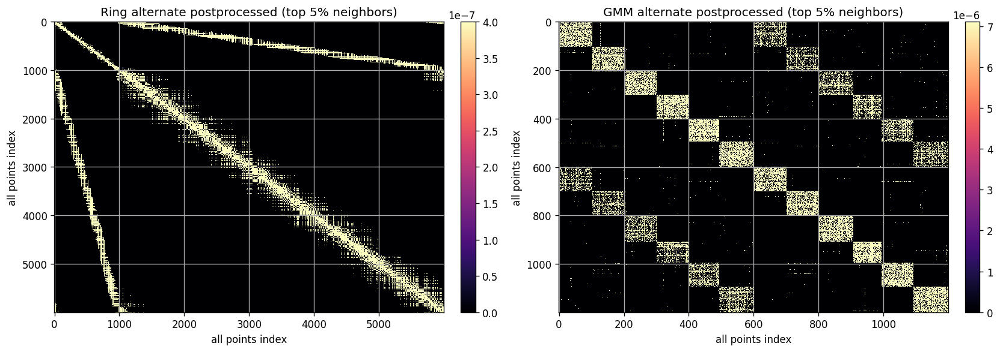

In [25]:
A_ring_alt_pct_neighbors, A_gmm_alt_pct_neighbors = [alt_prepare_matrix(A, P, diag_threshold=0.10) for A, P in ((A_ring_alt_pct_neighbors, P_ring_alt_pct_neighbors), (A_gmm_alt_pct_neighbors, P_gmm_alt_pct_neighbors))]
A_ring_alt_pct_neighbors_post = alt_postprocess_matrix(A_ring_alt_pct_neighbors)
A_gmm_alt_pct_neighbors_post = alt_postprocess_matrix(A_gmm_alt_pct_neighbors)

print("Alt pct-neighbors ring: nnz =", np.count_nonzero(A_ring_alt_pct_neighbors_post), "sum =", A_ring_alt_pct_neighbors_post.sum())
print("Alt pct-neighbors gmm : nnz =", np.count_nonzero(A_gmm_alt_pct_neighbors_post),  "sum =", A_gmm_alt_pct_neighbors_post.sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, A, title in [
    (axes[0], A_ring_alt_pct_neighbors_post, f"Ring alternate postprocessed (top {alt_p_neighbors:.0%} neighbors)"),
    (axes[1], A_gmm_alt_pct_neighbors_post,  f"GMM alternate postprocessed (top {alt_p_neighbors:.0%} neighbors)"),
]:
    disp = np.maximum(A, 0.0)
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto",
                   vmin=0.0, vmax=float(disp.max()) if disp.size else 1.0)
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


### top percentage of probability mass


Alt pct-mass ring: nnz = 5448104 sum = 1.0
Alt pct-mass gmm : nnz = 325514 sum = 0.9999999999999998


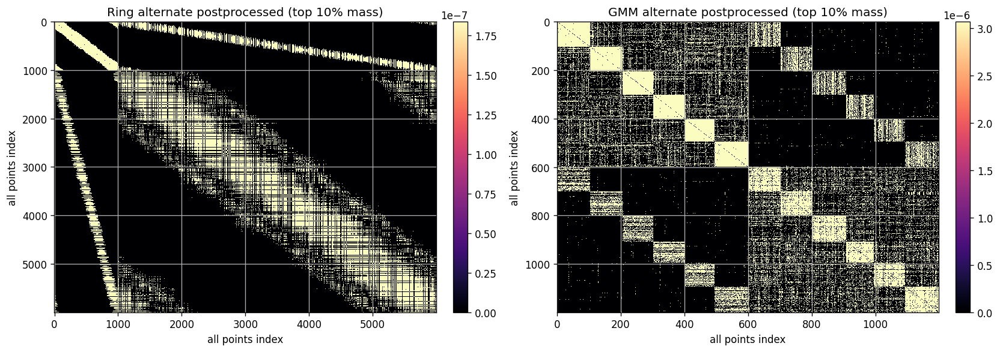

In [136]:
A_ring_alt_pct_mass, A_gmm_alt_pct_mass = [alt_prepare_matrix(A, P, diag_threshold=0.01) for A, P in ((A_ring_alt_pct_mass, P_ring_alt_pct_mass), (A_gmm_alt_pct_mass, P_gmm_alt_pct_mass))]
A_ring_alt_pct_mass_post = alt_postprocess_matrix(A_ring_alt_pct_mass)
A_gmm_alt_pct_mass_post = alt_postprocess_matrix(A_gmm_alt_pct_mass)

print("Alt pct-mass ring: nnz =", np.count_nonzero(A_ring_alt_pct_mass_post), "sum =", A_ring_alt_pct_mass_post.sum())
print("Alt pct-mass gmm : nnz =", np.count_nonzero(A_gmm_alt_pct_mass_post),  "sum =", A_gmm_alt_pct_mass_post.sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, A, title in [
    (axes[0], A_ring_alt_pct_mass_post, f"Ring alternate postprocessed (top {alt_p_mass:.0%} mass)"),
    (axes[1], A_gmm_alt_pct_mass_post,  f"GMM alternate postprocessed (top {alt_p_mass:.0%} mass)"),
]:
    disp = np.maximum(A, 0.0)
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto",
                   vmin=0.0, vmax=float(disp.max()) if disp.size else 1.0)
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


### values above percentage of top value


Alt above-top ring: nnz = 5912988 sum = 1.0
Alt above-top gmm : nnz = 161266 sum = 1.0


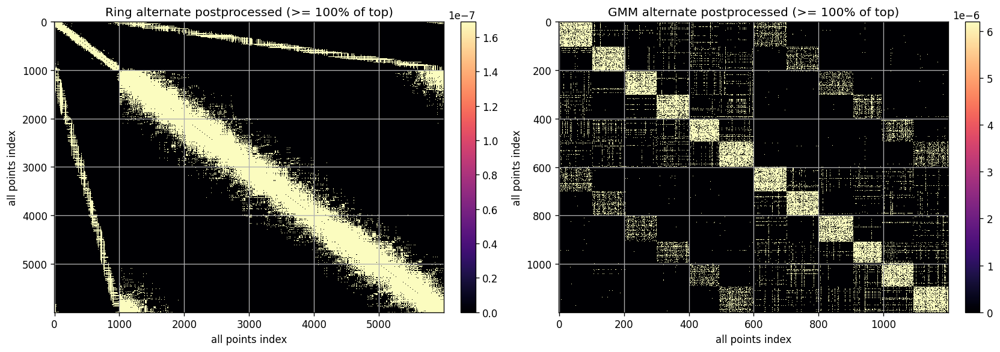

In [ ]:
A_ring_alt_above_top, A_gmm_alt_above_top = [alt_prepare_matrix(A, P, diag_threshold=0.01) for A, P in ((A_ring_alt_above_top, P_ring_alt_above_top), (A_gmm_alt_above_top, P_gmm_alt_above_top))]
A_ring_alt_above_top_post = alt_postprocess_matrix(A_ring_alt_above_top)
A_gmm_alt_above_top_post = alt_postprocess_matrix(A_gmm_alt_above_top)

print("Alt above-top ring: nnz =", np.count_nonzero(A_ring_alt_above_top_post), "sum =", A_ring_alt_above_top_post.sum())
print("Alt above-top gmm : nnz =", np.count_nonzero(A_gmm_alt_above_top_post),  "sum =", A_gmm_alt_above_top_post.sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, A, title in [
    (axes[0], A_ring_alt_above_top_post, f"Ring alternate postprocessed (>= {alt_p_top:.0%} of top)"),
    (axes[1], A_gmm_alt_above_top_post,  f"GMM alternate postprocessed (>= {alt_p_top:.0%} of top)"),
]:
    disp = np.maximum(A, 0.0)
    im = ax.imshow(disp, cmap="magma", interpolation="nearest", aspect="auto",
                   vmin=0.0, vmax=float(disp.max()) if disp.size else 1.0)
    ax.set_title(title)
    ax.set_xlabel("all points index")
    ax.set_ylabel("all points index")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## Alternate Step 6: compute tSNE embeddings


In [26]:
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from openTSNE import TSNE
from openTSNE.affinity import Affinities

if "run_tsne_from_graph" not in globals():
    def run_tsne_from_graph(G, seed=0, n_epochs=200):
        G = np.asarray(G, dtype=float)
        G = np.nan_to_num(G, nan=0.0, posinf=0.0, neginf=0.0)
        G[G < 0] = 0.0
        np.fill_diagonal(G, 0.0)
        s = G.sum()
        if s <= 0:
            raise ValueError("Graph has zero total mass.")
        G = G / s

        n = G.shape[0]
        init = np.random.RandomState(seed).randn(n, 2) * 1e-4
        n_early = n_epochs // 3
        n_late = n_epochs - n_early

        affinities = Affinities()
        affinities.P = sp.csr_matrix(G)

        embedder = TSNE(
            n_components=2,
            random_state=seed,
            verbose=True,
            early_exaggeration_iter=n_early,
            n_iter=n_late,
        )
        return embedder.fit(affinities=affinities, initialization=init)

if "plot_tsne_pair" not in globals():
    def plot_tsne_pair(emb_ring, emb_gmm, title_ring, title_gmm):
        ring_colors = np.array(["r"] * n0_ring + ["b"] * n1_ring)
        gmm_colors  = np.array(["r"] * gmm_n0 + ["b"] * gmm_n1)

        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        o0 = np.random.permutation(len(ring_colors))
        axes[0].scatter(*emb_ring[o0].T, s=1, c=ring_colors[o0])
        axes[0].set_aspect("equal")
        axes[0].axis("off")
        axes[0].set_title(title_ring)

        o1 = np.random.permutation(len(gmm_colors))
        axes[1].scatter(*emb_gmm[o1].T, s=1, c=gmm_colors[o1])
        axes[1].set_aspect("equal")
        axes[1].axis("off")
        axes[1].set_title(title_gmm)

        plt.tight_layout()
        plt.show()


### top percentage of neighbors


--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence 2.6303, 50 iterations in 1.7080 sec
   --> Time elapsed: 2.18 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 0.7679, 50 iterations in 1.4305 sec
Iteration  100, KL divergence 0.7668, 50 iterations in 1.4690 sec
   --> Time elapsed: 3.86 seconds
--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggera

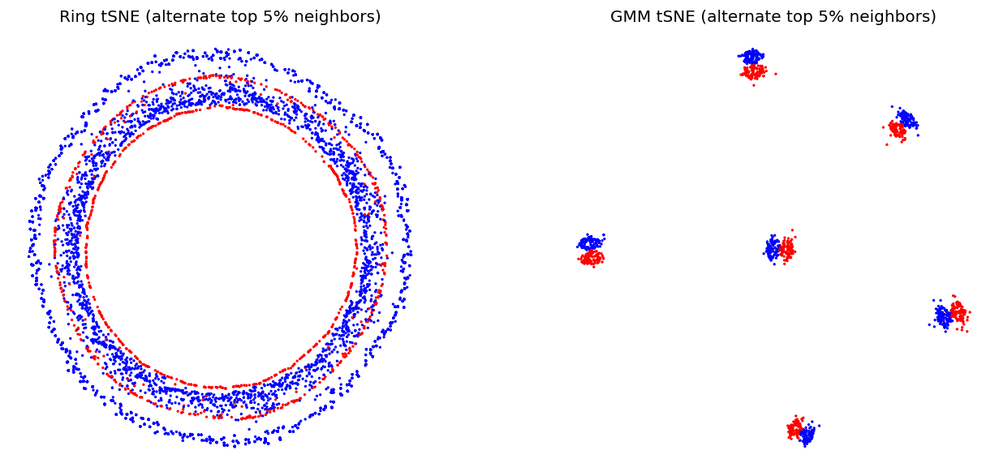

In [27]:
ring_embd_alt_pct_neighbors = run_tsne_from_graph(A_ring_alt_pct_neighbors_post, seed=0, n_epochs=200)
gmm_embd_alt_pct_neighbors  = run_tsne_from_graph(A_gmm_alt_pct_neighbors_post,  seed=0, n_epochs=200)

plot_tsne_pair(
    ring_embd_alt_pct_neighbors,
    gmm_embd_alt_pct_neighbors,
    f"Ring tSNE (alternate top {alt_p_neighbors:.0%} neighbors)",
    f"GMM tSNE (alternate top {alt_p_neighbors:.0%} neighbors)",
)


### top percentage of probability mass


--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence -1.8168, 50 iterations in 5.7188 sec
   --> Time elapsed: 7.26 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 0.4996, 50 iterations in 6.1946 sec
Iteration  100, KL divergence 0.4993, 50 iterations in 6.0583 sec
   --> Time elapsed: 16.08 seconds
--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exagge

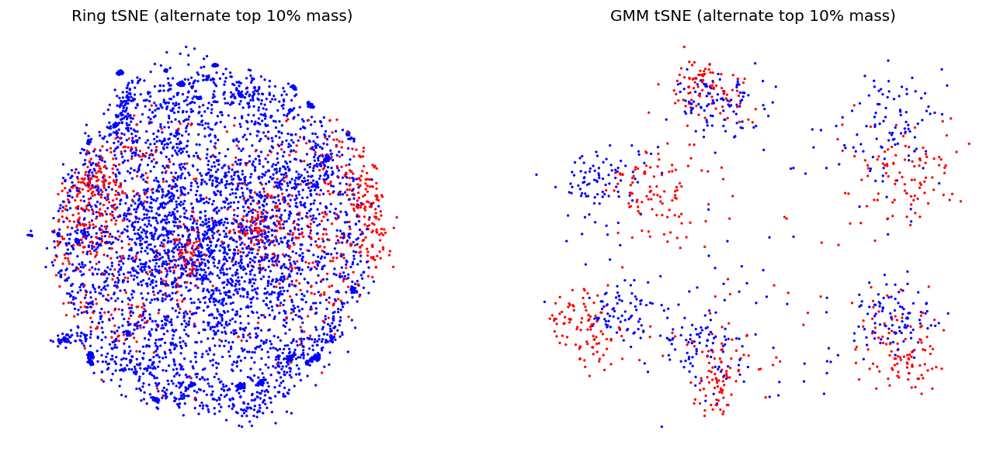

In [29]:
ring_embd_alt_pct_mass = run_tsne_from_graph(A_ring_alt_pct_mass_post, seed=0, n_epochs=200)
gmm_embd_alt_pct_mass  = run_tsne_from_graph(A_gmm_alt_pct_mass_post,  seed=0, n_epochs=200)

plot_tsne_pair(
    ring_embd_alt_pct_mass,
    gmm_embd_alt_pct_mass,
    f"Ring tSNE (alternate top {alt_p_mass:.0%} mass)",
    f"GMM tSNE (alternate top {alt_p_mass:.0%} mass)",
)


### values above percentage of top value


--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence -1.5349, 50 iterations in 5.6247 sec
   --> Time elapsed: 7.14 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 0.5140, 50 iterations in 5.8800 sec
Iteration  100, KL divergence 0.5130, 50 iterations in 5.7910 sec
   --> Time elapsed: 15.37 seconds
--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exagge

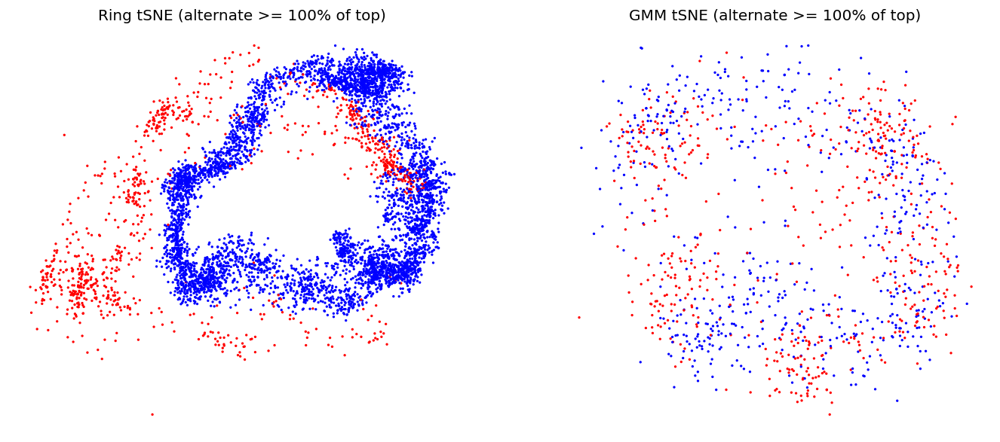

In [30]:
ring_embd_alt_above_top = run_tsne_from_graph(A_ring_alt_above_top_post, seed=0, n_epochs=200)
gmm_embd_alt_above_top  = run_tsne_from_graph(A_gmm_alt_above_top_post,  seed=0, n_epochs=200)

plot_tsne_pair(
    ring_embd_alt_above_top,
    gmm_embd_alt_above_top,
    f"Ring tSNE (alternate >= {alt_p_top:.0%} of top)",
    f"GMM tSNE (alternate >= {alt_p_top:.0%} of top)",
)


## To Do's 

- Fix quantile mapping: Take e.g. 5th and 95th quantile --> set this to 0 and 100th quantile to make the curve more spikey
- find out how kNN implementation sparsifies off diagonal blocks
- find out why embeddings for kNN and top percentage neighbours look different for settings where both solutions should be the same
- sparsify OT plan instead of 4 block matrix (diagonal blocks will not be sparse, choose threshold or sparsify again)
- principled way to choose epsilon --> maybe choose it based on the perplexity of the distributions (think again about how that might work)